# Aircraft sound as a geolocation signal
## One-notebook reproducible walkthrough
**James N. Jean IV · Applied signal processing and inverse problems**

This single notebook reproduces the public retained-data analysis, figures and synthetic propagation checks without downloading any project files. The small sanitized input tables and propagation functions are embedded below. It runs without network access after installing Python dependencies.

**Install once:** `python -m pip install numpy pandas matplotlib jupyterlab ipykernel`

Then open this file in JupyterLab and choose **Restart Kernel and Run All Cells**. Expected runtime is seconds to a few minutes on a typical laptop.

### Scope and provenance
This is a post-disclosure retrospective analysis: aircraft identity and approximate location were known to the analyst but excluded from fitting inputs. A-27 denotes the participant-supplied aircraft. The target is first by curve RMS under two models, not the winner of every objective. The reference is approximate and the reported distances are not confidence radii.

The notebook reproduces **public table-based results and physics checks**, not the original private audio extraction or full global trajectory/environment search. Those steps require recordings, flight tracks and terrain/weather inputs intentionally absent here. No private coordinates, real aircraft identifiers, exact recording timestamps or source audio are embedded.

### Reading order
1. Embedded evidence and measurement gap
2. Candidate comparison and rank sensitivity
3. Scalar validation
4. Geometry: altitude, ground elevation and slant range
5. Synthetic propagation checks and non-uniqueness

The technical manuscript and source archive remain available in the same GitHub project folder.

In [1]:
from io import StringIO
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':125,'axes.spines.top':False,'axes.spines.right':False})
INPUTS = {'measured_curve.csv': 'elapsed_s,common_spacing_hz,n_harmonics,harmonic_scatter,clip_index\n10,25.75009489085843,2,0.0063415657965793,1\n12,25.779135235802563,2,0.0082662646905436,1\n14,25.84211877029926,2,0.0049664307790349,1\n16,25.901941690668064,1,,1\n18,26.017165091586392,3,0.0132813020040504,1\n20,26.0638901086445,3,0.0138790648827157,1\n22,26.06792022099762,2,0.0240278349557982,1\n24,25.947684528439588,2,0.2648632641012303,1\n26,26.16587195605319,3,0.1146089360890043,1\n28,26.183595209725528,2,0.0196127429304398,1\n30,26.114508816540987,3,0.0009790120581517,1\n32,26.110482541705075,2,0.0309054744159944,1\n34,26.060026102845505,3,0.0355404207549414,1\n36,26.04745953887253,3,0.0034315691133595,1\n38,26.01347078531878,2,0.0090768357969126,1\n40,26.00796705698541,3,0.0058462465495599,1\n42,25.99896261052233,3,0.0281026616744725,1\n44,25.94155079732816,3,0.0096627206025754,1\n46,25.86955184075515,3,0.0031513910515089,1\n48,25.833418753642924,4,0.0068789465221455,1\n50,25.765095558059315,4,0.0130836117049056,1\n52,25.692059557647468,4,0.0102022153757285,1\n54,25.611887996709957,3,0.0143315217479657,1\n56,25.50226981892492,4,0.0268264959014236,1\n58,25.357986352793663,3,0.0069765735411433,1\n60,25.22570890581611,3,0.0162058340691451,1\n62,25.103285266701537,3,0.0081060342402124,1\n64,24.986591450063408,4,0.0150370732297139,1\n66,24.884488946021264,4,0.0049509115441299,1\n68,24.812082517201823,3,0.0063194727438399,1\n88,23.892428179445005,2,0.0227191782976545,2\n90,23.73679009173261,2,0.0305110951849683,2\n92,23.57543391158625,2,0.0041858471034328,2\n94,23.381005712161933,1,,2\n96,23.18988640861931,2,0.0203891490194234,2\n98,23.040009970669573,2,0.0175122270630823,2\n100,22.834449703546504,1,,2\n102,22.601643857563893,1,,2\n104,22.27692060885615,1,,2\n106,21.95806357985853,1,,2\n108,21.673753166585577,2,0.0582151341608421,2\n110,21.445037619345683,1,,2\n118,20.50005321354645,1,,2\n122,20.06221643722642,1,,2\n124,19.90695596431901,1,,2\n126,19.767451384323167,3,0.0397676429961497,2\n128,19.642433693200232,2,0.0003098885109345,2\n130,19.47666220765512,2,0.0044454648470935,2\n132,19.37150301464768,2,0.009807652299349,2\n134,19.257890057008147,2,0.0005859061089978,2\n136,19.15613419136956,3,0.0083872273486282,2\n138,19.08588648629184,3,0.0036682621813224,2\n140,19.024117723485663,3,0.0034325417223187,2\n142,18.98060932202732,2,0.0003958835623853,2\n144,18.93791383289813,3,0.0054770923279678,2\n146,18.91878708638682,3,0.0079964074190382,2\n148,18.900144863680737,3,0.009148417972899,2\n150,18.883798750423363,3,0.0130859817972401,2\n152,18.837697490207336,2,0.013587319023326,2\n154,18.82698599175444,3,0.0017553695541281,2\n156,18.805204826921933,3,0.0036972818190688,2\n158,18.78951166472781,3,0.0017918316085149,2\n', 'corrected_candidate_scores.csv': 'label,type,cohort,constant_rms_rank,constant_rms_score,constant_brightness_rank,constant_brightness_score,drift3_rms_rank,drift3_rms_score,drift3_brightness_rank,drift3_brightness_score,status\nC-001,B789,corrected_capture_time_refinement,337,0.6705020153738839,255,6.998499189184342,339,0.6661111462032083,275,7.221361187519134,both source models covered\nC-002,B789,corrected_capture_time_refinement,202,0.31798309742000697,235,7.428994874628339,226,0.2945714692635852,222,8.51322608573696,both source models covered\nC-003,CRJ9,corrected_capture_time_refinement,295,0.4467094816636545,284,6.4157145929011365,306,0.4413668789056298,309,6.24363296426864,both source models covered\nC-004,A320,corrected_capture_time_refinement,296,0.4496892248486256,341,4.655457945494878,304,0.43397192878728097,346,4.411049345537786,both source models covered\nC-005,B738,corrected_capture_time_refinement,257,0.3905286590430378,335,4.876335363316541,281,0.3890295245930805,340,4.8258178077751674,both source models covered\nC-006,A21N,corrected_capture_time_refinement,208,0.32411027101450535,73,11.44218214605063,171,0.24198969629222156,111,11.368617239662676,both source models covered\nC-007,A332,corrected_capture_time_refinement,276,0.41903596962105005,302,5.96734863154059,278,0.38819956840338266,302,6.462857220233392,both source models covered\nC-008,A21N,corrected_capture_time_refinement,288,0.4381182410067444,332,4.978054467054234,279,0.3883111710527292,280,6.9277464373751645,both source models covered\nC-009,B738,corrected_capture_time_refinement,192,0.3076778146791597,181,8.557864529878113,217,0.28531430165600347,232,8.22602922979506,both source models covered\nC-010,AT72,corrected_capture_time_refinement,326,0.5523288641815358,263,6.805858518352618,316,0.46769809974806764,274,7.26684932090348,both source models covered\nC-011,Unknown,corrected_capture_time_refinement,294,0.44653595078450703,249,7.180229765098001,298,0.41955411232426604,301,6.502159282163763,both source models covered\nC-012,B77W,corrected_capture_time_refinement,187,0.3046562486860211,217,7.773801788938913,191,0.2591215708469879,210,8.739998276257259,both source models covered\nC-013,B190,corrected_capture_time_refinement,199,0.3161872730335234,204,8.009254460208256,225,0.2945330754825134,243,8.095837467450455,both source models covered\nC-014,A21N,corrected_capture_time_refinement,164,0.2810185739426349,218,7.719006557774584,193,0.26053523243117827,230,8.292066684931623,both source models covered\nC-015,C525,corrected_capture_time_refinement,338,0.6765711669412494,300,5.987216173797551,338,0.6611929643941707,330,5.293855408229313,both source models covered\nC-016,F406,corrected_capture_time_refinement,181,0.2980812670185708,270,6.758933319474058,211,0.27579627793880285,253,7.752633132117109,both source models covered\nC-017,BE20,corrected_capture_time_refinement,24,0.17011168168560425,33,12.237641489083913,49,0.15906094136565346,101,11.65595549505653,both source models covered\nC-018,B738,corrected_capture_time_refinement,323,0.5274751607977255,281,6.49767080645001,317,0.4677068348704578,308,6.2844098199870615,both source models covered\nC-019,DA42,corrected_capture_time_refinement,161,0.2797221591412027,108,10.648676306318022,154,0.22495250466571176,124,11.096742767589872,both source models covered\nC-020,PC12,corrected_capture_time_refinement,163,0.2808389916740341,152,9.565314404307346,190,0.25822160795256094,132,10.956432126590446,both source models covered\nC-021,A320,corrected_capture_time_refinement,333,0.6242643442136535,353,3.9027814795081452,334,0.6053859766440125,355,3.772285865820475,both source models covered\nC-022,A320,corrected_capture_time_refinement,279,0.42381990442129674,231,7.4652654362708155,282,0.389289169477972,261,7.606065698207658,both source models covered\nC-023,AT72,corrected_capture_time_refinement,259,0.3937692097734075,303,5.954145932758574,261,0.3531883344481395,310,6.241107320713541,both source models covered\nC-024,AT76,corrected_capture_time_refinement,213,0.328285388426596,258,6.911693543340132,208,0.2718785078645321,221,8.520575397410573,both source models covered\nC-025,A21N,corrected_capture_time_refinement,55,0.1947551641298778,83,11.297507704287979,86,0.1776412738466157,110,11.384836577795065,both source models covered\nC-026,Unknown,corrected_capture_time_refinement,305,0.47361147833894873,304,5.937164526629011,299,0.42467219347485263,288,6.755135794043316,both source models covered\nC-027,AT76,corrected_capture_time_refinement,105,0.2362325059178762,139,9.808889016645722,122,0.20331997600578536,152,10.651456222212236,both source models covered\nC-028,A21N,corrected_capture_time_refinement,151,0.274010884562246,197,8.163690225747768,150,0.2222403839919107,165,10.276226508230138,both source models covered\nC-029,SF34,corrected_capture_time_refinement,315,0.49364161816142366,345,4.360636472066325,315,0.4674529881150439,331,5.225359653163722,both source models covered\nC-030,SF34,corrected_capture_time_refinement,245,0.3694161456866519,299,6.03958387197079,248,0.32659441953329504,307,6.363427131495213,both source models covered\nC-031,SF34,corrected_capture_time_refinement,301,0.4612629660193918,351,4.027364097831949,302,0.42656561100747686,316,5.876540012245321,both source models covered\nC-032,AT75,corrected_capture_time_refinement,281,0.42513802166226194,247,7.208690420630521,291,0.401280881402645,278,7.058484411143722,both source models covered\nC-033,AT75,corrected_capture_time_refinement,328,0.5604181862318189,354,3.617691650656993,328,0.5280010471320349,328,5.302884080370629,both source models covered\nC-034,B38M,corrected_capture_time_refinement,244,0.3671442872193836,180,8.621980387839708,251,0.33862490718618865,192,9.474241494955105,both source models covered\nC-035,C172,corrected_capture_time_refinement,124,0.2564195949912012,230,7.495252716452705,164,0.23551297467585278,194,9.4494488525693,both source models covered\nC-036,C172,corrected_capture_time_refinement,2,0.12243451105238809,3,13.491007250193077,3,0.11924394847168192,6,13.788037523375118,both source models covered\nC-037,C208,corrected_capture_time_refinement,176,0.2949049943951183,271,6.713298851361378,180,0.25080126148300075,204,8.916037223325556,both source models covered\nC-038,A333,corrected_capture_time_refinement,235,0.3487677063449513,243,7.26047142223349,244,0.31866776410153175,286,6.771613195047532,both source models covered\nC-039,B78X,corrected_capture_time_refinement,344,0.8077431831594517,286,6.388755200457657,345,0.7895356589684351,323,5.559270348488056,both source models covered\nC-040,EC25,corrected_capture_time_refinement,39,0.18143857268161423,80,11.385250845106182,84,0.17715706715033253,122,11.131404139510604,both source models covered\nC-041,AT75,corrected_capture_time_refinement,342,0.7791858651240161,349,4.162394755248881,340,0.6764791061975477,345,4.422939956530284,both source models covered\nC-042,AT75,corrected_capture_time_refinement,262,0.39424520549568043,130,10.086106916572133,274,0.3789654412658992,177,10.037654925094103,both source models covered\nC-043,A321,corrected_capture_time_refinement,106,0.23631935002638982,172,8.987382634252697,133,0.2088538338406782,170,10.14940357291823,both source models covered\nC-044,DH8D,corrected_capture_time_refinement,86,0.21990940559591216,11,12.864181953227435,135,0.2092376769258751,18,12.917979116761469,both source models covered\nC-045,A20N,corrected_capture_time_refinement,354,1.1680503036909435,261,6.826072132309629,355,1.1703333594172047,270,7.352159297244272,both source models covered\nC-046,B744,corrected_capture_time_refinement,159,0.27751770633397105,250,7.157649817706197,175,0.24763572865591427,250,7.8776230670806004,both source models covered\nC-047,B77W,corrected_capture_time_refinement,310,0.47834560746938776,327,5.1897488123044715,297,0.4151414621997578,283,6.860551912699582,both source models covered\nC-048,A320,corrected_capture_time_refinement,350,0.9605822263245427,322,5.311183034757024,351,0.9597216327939111,315,5.885874871571667,both source models covered\nC-049,B738,corrected_capture_time_refinement,65,0.2040880259605314,66,11.663436669981515,101,0.18675173394614863,56,12.323051687592747,both source models covered\nC-050,B789,corrected_capture_time_refinement,141,0.26923472607103527,160,9.226870701563573,141,0.21295421990253002,155,10.571528120435378,both source models covered\nC-051,AJ27,corrected_capture_time_refinement,206,0.32081380404509846,188,8.328060014077568,240,0.3153238013907156,238,8.164290497692534,both source models covered\nC-052,Y12,corrected_capture_time_refinement,70,0.20694028929670322,72,11.540447083999382,123,0.20371036490705288,112,11.343557475334089,both source models covered\nC-053,BE58,corrected_capture_time_refinement,140,0.2664051564650616,242,7.317046932258099,202,0.26619696880879035,266,7.402605112072406,both source models covered\nC-054,C172,corrected_capture_time_refinement,297,0.45065804236246465,133,10.004172570537543,310,0.4494709033716722,172,10.145101240779908,both source models covered\nC-055,B350,corrected_capture_time_refinement,123,0.25582425317827473,175,8.80324819942315,145,0.218415301487889,179,9.990878207600622,both source models covered\nC-056,C337,corrected_capture_time_refinement,128,0.2587519037454913,190,8.292552770565928,146,0.21919682697496246,196,9.32343468678091,both source models covered\nC-057,SR22,corrected_capture_time_refinement,138,0.2652780125522571,209,7.90343509922692,155,0.22536090848129914,209,8.742189964008217,both source models covered\nC-058,C172,corrected_capture_time_refinement,75,0.21154405627019043,52,11.937773436835045,53,0.16075101846707093,37,12.579119621646013,both source models covered\nC-059,PA44,corrected_capture_time_refinement,79,0.21803898439596736,98,10.860290378098238,95,0.18154079426209718,134,10.950971924546135,both source models covered\nC-060,R44,corrected_capture_time_refinement,5,0.1398873100481068,9,13.067028063500532,9,0.13534322622198228,12,13.14074740036654,both source models covered\nC-061,DH8D,corrected_capture_time_refinement,147,0.27265688280966455,24,12.456082762274173,186,0.2548790570624205,109,11.434339392075055,both source models covered\nC-062,DH8D,corrected_capture_time_refinement,252,0.38075451635440466,330,5.106071402154432,270,0.3737131191757722,332,5.166367315168617,both source models covered\nC-063,C208,corrected_capture_time_refinement,110,0.24246615156091134,125,10.213877099411228,110,0.1928783571746466,131,10.984756150558745,both source models covered\nC-064,SR22,corrected_capture_time_refinement,97,0.22910496295980717,131,10.031683786346083,72,0.1706094695370819,80,12.010508404813315,both source models covered\nC-065,BE20,corrected_capture_time_refinement,269,0.4031183727764592,274,6.605654878071302,267,0.36647838857155746,268,7.376878055033929,both source models covered\nC-066,PC12,corrected_capture_time_refinement,339,0.6989241397208188,254,7.002147496993896,335,0.6227692563530701,242,8.096818708622854,both source models covered\nC-067,BE20,corrected_capture_time_refinement,270,0.40799140271869244,310,5.720360241342695,271,0.3764449080340015,267,7.378665762514278,both source models covered\nC-068,C208,corrected_capture_time_refinement,167,0.28369031744322193,265,6.78160883319234,162,0.23363386162051636,208,8.785815863527578,both source models covered\nC-069,DH8D,corrected_capture_time_refinement,143,0.2712658764569094,240,7.376165546998127,183,0.25277394830926486,273,7.309335778560973,both source models covered\nC-070,DH8D,corrected_capture_time_refinement,304,0.47042568402022333,317,5.480055531930314,305,0.4365529723034803,325,5.390373409692973,both source models covered\nC-071,P28A,corrected_capture_time_refinement,289,0.4392860748906853,189,8.313099223218982,266,0.36437758925643815,223,8.480102647331387,both source models covered\nC-072,C182,corrected_capture_time_refinement,300,0.458618110296852,101,10.825664635760695,307,0.4436980225429552,168,10.250876236344242,both source models covered\nC-073,BL8,corrected_capture_time_refinement,23,0.16894507649676255,49,11.970129641144005,61,0.16303946341277015,42,12.504815395229848,both source models covered\nC-074,C208,corrected_capture_time_refinement,115,0.24551598935940855,128,10.145245569829383,113,0.19340404756256854,135,10.94278545388857,both source models covered\nC-075,C208,corrected_capture_time_refinement,94,0.2277821746919073,153,9.523346344284215,139,0.20985138767532244,167,10.261951532721916,both source models covered\nC-076,AS50,corrected_capture_time_refinement,280,0.42475822266299706,225,7.561638969034713,229,0.29874859336373794,191,9.478904320377747,both source models covered\nC-077,C152,corrected_capture_time_refinement,93,0.2274962998996086,146,9.725355028597004,41,0.1567722639453351,76,12.079541485652777,both source models covered\nC-078,SF34,corrected_capture_time_refinement,317,0.5088506624862965,306,5.898023767999541,312,0.45414402223009137,293,6.607510307448742,both source models covered\nC-079,PC12,corrected_capture_time_refinement,234,0.34736854292300523,222,7.634293579760344,239,0.31520404873448776,254,7.747651561485004,both source models covered\nC-080,DH8C,corrected_capture_time_refinement,293,0.44498666993809455,343,4.588563176417468,295,0.4142818200870941,335,5.068756455289148,both source models covered\nC-081,A139,corrected_capture_time_refinement,59,0.19778098630256907,18,12.672099596898892,109,0.19203246304196775,96,11.779138666463206,both source models covered\nC-082,BCS3,corrected_capture_time_refinement,103,0.234286852288627,206,7.9984100072062425,159,0.23253584319626508,260,7.634965820352948,both source models covered\nC-083,BCS3,corrected_capture_time_refinement,351,0.9892861408583974,356,3.1206047540778625,350,0.9472415748402281,357,3.0170143373295764,both source models covered\nC-084,DA42,corrected_capture_time_refinement,173,0.29251293943724754,106,10.746956417485936,215,0.28385087451813473,107,11.44189888696663,both source models covered\nC-085,DA42,corrected_capture_time_refinement,153,0.27501939156418936,196,8.172081078157484,198,0.2643765332108581,207,8.856575144736645,both source models covered\nC-086,C172,corrected_capture_time_refinement,83,0.21932535642214515,138,9.844591363515255,68,0.16798185994729953,143,10.793479148711388,both source models covered\nC-087,B738,corrected_capture_time_refinement,240,0.3566583726182629,309,5.729011526559701,252,0.339363482027627,269,7.361140807753685,both source models covered\nC-088,DA40,corrected_capture_time_refinement,154,0.2751542082333731,90,11.118430853230622,173,0.24318923241591645,22,12.820055044898258,both source models covered\nC-089,DA40,corrected_capture_time_refinement,216,0.3315787696021023,104,10.800533612922067,201,0.26565060254892997,151,10.69578147541819,both source models covered\nC-090,RV12,corrected_capture_time_refinement,160,0.2786808016894071,213,7.8412989150079975,212,0.27755647405271966,228,8.351313634906065,both source models covered\nC-091,XL2,corrected_capture_time_refinement,9,0.1529936080676501,19,12.605118208951557,14,0.14214924949855837,30,12.67543331356598,both source models covered\nC-092,C172,corrected_capture_time_refinement,52,0.19351176546070797,57,11.850896180829212,99,0.18448648153904895,65,12.221931715687886,both source models covered\nC-093,C172,corrected_capture_time_refinement,195,0.3100710309711556,162,9.190647562734519,89,0.17913457809679384,70,12.153903416824027,both source models covered\nC-094,SF34,corrected_capture_time_refinement,219,0.3334743941031655,288,6.374157820527673,237,0.3104375070691202,282,6.873086948851927,both source models covered\nC-095,SF34,corrected_capture_time_refinement,261,0.3939973496504312,224,7.607488971103999,288,0.3937384776030013,300,6.507303770662225,both source models covered\nC-096,SF34,corrected_capture_time_refinement,222,0.33717844470148134,201,8.052570649993294,222,0.29140812613114975,252,7.783448592915841,both source models covered\nC-097,SF34,corrected_capture_time_refinement,166,0.2831711629156793,234,7.438969343856229,174,0.24502082954251075,226,8.438301259215656,both source models covered\nC-098,P28A,corrected_capture_time_refinement,200,0.3174805129481658,136,9.949890800068145,96,0.18326950010131382,102,11.645792752969092,both source models covered\nC-099,B350,corrected_capture_time_refinement,306,0.4746942338953969,344,4.377601927784504,309,0.44895347040708294,339,4.826547346195103,both source models covered\nC-100,DH8D,corrected_capture_time_refinement,237,0.3505996280964554,227,7.548710986311336,257,0.3458068367676202,276,7.14048051292142,both source models covered\nC-101,G222,corrected_capture_time_refinement,283,0.4298602233229283,311,5.719159031463575,285,0.39104891403059683,299,6.510998342341158,both source models covered\nC-102,A20N,corrected_capture_time_refinement,217,0.33169159207637233,95,10.985926138673818,218,0.28581366887767473,141,10.817699048151725,both source models covered\nC-103,AT76,corrected_capture_time_refinement,275,0.4178558496618656,342,4.647313694762537,284,0.3895648677780869,338,4.846134368326474,both source models covered\nC-104,AT76,corrected_capture_time_refinement,287,0.4380012857755281,314,5.5790816111346775,294,0.41219993235885677,312,6.212020906788998,both source models covered\nC-105,B38M,corrected_capture_time_refinement,285,0.4370536397652871,291,6.292308378180335,296,0.4148028994492224,305,6.402181186919872,both source models covered\nC-106,A21N,corrected_capture_time_refinement,308,0.47612577832237335,328,5.134199910685991,313,0.4570511263682929,314,6.082666375386509,both source models covered\nC-107,Unknown,corrected_capture_time_refinement,31,0.17244668561430915,60,11.74989683845849,46,0.15876692852916294,91,11.832243405266063,both source models covered\nC-108,AT76,corrected_capture_time_refinement,258,0.3911573243569967,287,6.385657969256536,256,0.34544402086400955,290,6.66987250582684,both source models covered\nC-109,A139,corrected_capture_time_refinement,131,0.2594358421566751,75,11.438638611132607,32,0.15214313000675292,23,12.772994373353797,both source models covered\nC-110,BE58,corrected_capture_time_refinement,189,0.3050049729954713,259,6.910635592716799,196,0.26302467459917706,271,7.344498028269591,both source models covered\nC-111,A359,corrected_capture_time_refinement,125,0.2566622878239896,194,8.18295612153874,172,0.24226384253765448,245,8.046377869229348,both source models covered\nC-112,B738,corrected_capture_time_refinement,231,0.346475500970791,285,6.414510953894945,238,0.3108193115626335,291,6.6557158459651795,both source models covered\nC-113,B763,corrected_capture_time_refinement,358,1.9828050974789015,358,1.6249691352435554,358,1.8445463563173274,350,4.023312225200999,both source models covered\nC-114,B763,corrected_capture_time_refinement,253,0.38324284097805084,296,6.204809811149858,259,0.34892817156325284,258,7.66683185024308,both source models covered\nC-115,R66,corrected_capture_time_refinement,158,0.2774988522694369,141,9.799718414983621,119,0.19734584773986044,55,12.327467633512335,both source models covered\nC-116,B77W,corrected_capture_time_refinement,330,0.590380365351733,151,9.59129710451184,329,0.5331532009246284,200,9.158653785056654,both source models covered\nC-117,SR22,corrected_capture_time_refinement,60,0.198722070085684,132,10.015003613822318,112,0.19331386035968293,160,10.383659636683173,both source models covered\nC-118,B738,corrected_capture_time_refinement,282,0.42817179500192715,312,5.704201859936916,301,0.4265276360853089,322,5.596386703911369,both source models covered\nC-119,B738,corrected_capture_time_refinement,169,0.28466512102718294,112,10.479602156886427,184,0.25395153502564927,181,9.85304482922685,both source models covered\nC-120,B738,corrected_capture_time_refinement,357,1.4060575716151782,347,4.336437034364048,357,1.2914128167253172,343,4.500508998023594,both source models covered\nC-121,A139,corrected_capture_time_refinement,139,0.2656455682040883,178,8.677080829304286,124,0.20383357858583814,153,10.649900194049362,both source models covered\nC-122,C68A,corrected_capture_time_refinement,226,0.34307924766031633,114,10.410547639985602,216,0.2851910224582621,94,11.780097433076177,both source models covered\nC-123,AT76,corrected_capture_time_refinement,221,0.3369107736205947,239,7.377367918659424,223,0.2929909514696253,244,8.063219778453856,both source models covered\nC-124,AT76,corrected_capture_time_refinement,,,,,321,0.4843919480329174,356,3.407298332210844,drift model only\nC-125,B77W,corrected_capture_time_refinement,320,0.5225032064429472,313,5.585203491056465,323,0.4909525151977044,292,6.636290448751092,both source models covered\nC-126,B38M,corrected_capture_time_refinement,318,0.5131984597609358,355,3.406244006305262,324,0.5012460456835277,353,3.9696144836669895,both source models covered\nC-127,A321,corrected_capture_time_refinement,,,,,,,,,no covered retained refinement mode\nC-128,SR22,corrected_capture_time_refinement,22,0.16798713937243515,27,12.356275154454362,65,0.16626041583640044,26,12.72835471653324,both source models covered\nC-129,B77L,corrected_capture_time_refinement,267,0.4021179646835286,177,8.72425024137609,268,0.3697822622352304,213,8.659528299625329,both source models covered\nC-130,DA42,corrected_capture_time_refinement,82,0.21902665915899996,21,12.501110861608984,24,0.15012605201191115,1,14.432822927932751,both source models covered\nC-131,B407,corrected_capture_time_refinement,265,0.3976403326954651,126,10.197673915902493,262,0.35815137965594607,116,11.202916549811835,both source models covered\nC-132,Unknown,corrected_capture_time_refinement,172,0.2905361759021109,195,8.181578264862036,168,0.24012711785647808,190,9.512219479543477,both source models covered\nC-133,A320,corrected_capture_time_refinement,327,0.556273769853645,326,5.20183571115138,325,0.5104693610090147,341,4.734629432790204,both source models covered\nC-134,C208,corrected_capture_time_refinement,205,0.320443589374763,223,7.6077430540642865,214,0.28189220762545386,233,8.216315279823803,both source models covered\nC-135,GLF5,corrected_capture_time_refinement,271,0.4127555533684697,282,6.479955352660107,273,0.37876756079561974,287,6.761905297313908,both source models covered\nC-136,BE20,corrected_capture_time_refinement,263,0.3962776065619166,307,5.8397784229911265,276,0.38229577966932754,306,6.387952399738777,both source models covered\nC-137,C208,corrected_capture_time_refinement,316,0.4963737056671396,278,6.536661618083992,322,0.4890524793701396,296,6.596871691087684,both source models covered\nC-138,EC35,corrected_capture_time_refinement,45,0.1858151587541568,65,11.66389474942343,22,0.148293757393858,62,12.250525369308628,both source models covered\nC-139,C208,corrected_capture_time_refinement,177,0.29578512893848125,205,8.0031826494153,179,0.2499204560266923,225,8.447918294573574,both source models covered\nC-140,B190,corrected_capture_time_refinement,277,0.41937580136420033,339,4.7010738499765345,286,0.39171640651508355,321,5.666425224462609,both source models covered\nC-141,EC45,corrected_capture_time_refinement,49,0.190285928395698,15,12.780414433019939,71,0.1697399994172471,54,12.340038578599101,both source models covered\nC-142,C172,corrected_capture_time_refinement,58,0.19667817020627837,37,12.16022073300404,66,0.166332559994239,61,12.265881699728652,both source models covered\nC-143,DA40,corrected_capture_time_refinement,77,0.21442583512377383,50,11.95979161664937,111,0.19293389705163302,48,12.405114117579204,both source models covered\nC-144,B763,corrected_capture_time_refinement,321,0.5257718322007975,185,8.39908075434997,326,0.5108354457294901,203,8.997338270395815,both source models covered\nC-145,BE58,corrected_capture_time_refinement,212,0.32806134366271583,155,9.480558698757072,245,0.31901481758011935,220,8.541895374541932,both source models covered\nC-146,B39M,corrected_capture_time_refinement,239,0.35610329777073024,199,8.108019169649225,235,0.30838994768516886,197,9.286274511555183,both source models covered\nC-147,B407,corrected_capture_time_refinement,13,0.15611685281661705,14,12.81358118511201,31,0.1516643511621718,24,12.744400660773787,both source models covered\nC-148,TB20,corrected_capture_time_refinement,8,0.15014016188020984,13,12.821471609842574,20,0.1480865707636816,38,12.578651667821998,both source models covered\nC-149,B763,corrected_capture_time_refinement,112,0.2427000871673922,173,8.985747251715276,161,0.2333314114245857,184,9.771094073729575,both source models covered\nC-150,PIAT,corrected_capture_time_refinement,130,0.25935991912197903,86,11.230268603977414,73,0.17074597851620557,66,12.202813136142707,both source models covered\nC-151,SR20,corrected_capture_time_refinement,71,0.2075675451580845,69,11.610558063882644,81,0.17524680577746304,77,12.03477663408559,both source models covered\nC-152,SW4,corrected_capture_time_refinement,194,0.30983123780672966,267,6.768885107716967,227,0.29597151107518366,295,6.598930451511157,both source models covered\nC-153,PC12,corrected_capture_time_refinement,193,0.3082312125834688,276,6.5627872643569845,220,0.288132507072357,294,6.602155205086415,both source models covered\nC-154,RV6,corrected_capture_time_refinement,18,0.16355197606622163,68,11.614235924256953,60,0.1621033396527596,73,12.118340924560744,both source models covered\nC-155,C172,corrected_capture_time_refinement,78,0.21790229141107254,167,9.08101796210636,78,0.1742928663530367,115,11.233911915520308,both source models covered\nC-156,E75L,corrected_capture_time_refinement,292,0.44338952564145273,331,4.988136754884607,293,0.4103598081350817,333,5.158976888450201,both source models covered\nC-157,P28A,corrected_capture_time_refinement,3,0.12413839064467717,4,13.414511314666933,4,0.12118741632964805,10,13.343944046254377,both source models covered\nC-158,PA44,corrected_capture_time_refinement,249,0.37413958608311065,318,5.4799908023721375,241,0.3164525038815715,129,11.002486905658042,both source models covered\nC-159,C152,corrected_capture_time_refinement,184,0.3036440902227839,198,8.15792454103985,149,0.2222056785732126,164,10.292458354111666,both source models covered\nC-160,EC45,corrected_capture_time_refinement,30,0.17208621150934075,53,11.931121064755931,48,0.15903367155931755,95,11.779368618626112,both source models covered\nC-161,B763,corrected_capture_time_refinement,201,0.3177070806997593,164,9.132768461255699,188,0.25613795687131824,174,10.12490222677199,both source models covered\nC-162,EC45,corrected_capture_time_refinement,16,0.16160322786242098,28,12.325918125469798,34,0.15432064211719007,43,12.489864904906305,both source models covered\nC-163,Unknown,corrected_capture_time_refinement,92,0.2269810850893587,92,11.008316823771711,11,0.13783941901649532,13,13.128922437523308,both source models covered\nC-164,BE95,corrected_capture_time_refinement,230,0.34647094621845065,232,7.450610404180477,228,0.29794860310006926,104,11.51605645737332,both source models covered\nC-165,B763,corrected_capture_time_refinement,236,0.35047543698830963,277,6.555613197052069,254,0.3423432408873436,303,6.429042476963376,both source models covered\nC-166,P28A,corrected_capture_time_refinement,246,0.37033532264023045,268,6.763628314351095,148,0.22208980248493318,183,9.798709842526062,both source models covered\nC-167,B06,corrected_capture_time_refinement,34,0.17914164482275485,43,12.094402907735734,76,0.17128644357925335,60,12.269215902742996,both source models covered\nC-168,Unknown,corrected_capture_time_refinement,121,0.2552883418420764,179,8.647724479298525,137,0.20948282888152117,182,9.842755842246593,both source models covered\nC-169,B763,corrected_capture_time_refinement,264,0.3967579572882389,147,9.702372251690358,255,0.344897294038991,187,9.708095468086594,both source models covered\nC-170,E75L,corrected_capture_time_refinement,325,0.5352996153508707,337,4.839521826246244,308,0.4458622329758149,326,5.38326770013351,both source models covered\nC-171,EC30,corrected_capture_time_refinement,32,0.17295459609540495,20,12.51854091348406,39,0.15601271739016787,20,12.851020964671433,both source models covered\nC-172,S22T,corrected_capture_time_refinement,175,0.29396262928948635,202,8.04415363621731,178,0.24952899122230787,219,8.55296943670414,both source models covered\nC-173,S22T,corrected_capture_time_refinement,210,0.32533755820464483,193,8.21481088212829,206,0.27139296106987987,205,8.91535483541583,both source models covered\nC-174,BCS3,corrected_capture_time_refinement,347,0.8781561628623459,333,4.960952142489723,348,0.8441223126505012,347,4.388847508124095,both source models covered\nC-175,PC12,corrected_capture_time_refinement,119,0.25276077273194214,192,8.225871512026494,163,0.23527483478388792,201,9.129680107449946,both source models covered\nC-176,A319,corrected_capture_time_refinement,203,0.31939807981674817,294,6.223436207079304,236,0.3095151849646732,304,6.417477348488144,both source models covered\nC-177,P28A,corrected_capture_time_refinement,10,0.153372500925001,30,12.301061567594086,25,0.15034294819547095,57,12.31331185053063,both source models covered\nC-178,P28A,corrected_capture_time_refinement,232,0.34650620314641495,210,7.89251358213898,152,0.223900460633054,79,12.011893107134119,both source models covered\nC-179,BE30,corrected_capture_time_refinement,345,0.8257293702456376,135,9.959163215423237,344,0.7885706228111534,235,8.193265309730803,both source models covered\nC-180,P28A,corrected_capture_time_refinement,233,0.3467555545717716,219,7.689386105462027,253,0.33946924087978125,255,7.734861619585811,both source models covered\nC-181,B763,corrected_capture_time_refinement,346,0.8266399070182365,158,9.31145963626488,346,0.8070869635833472,198,9.253763095066974,both source models covered\nC-182,PC12,corrected_capture_time_refinement,319,0.5150682090889029,272,6.69986494908095,320,0.4840871247123869,277,7.087489420168695,both source models covered\nC-183,P28A,corrected_capture_time_refinement,90,0.22318715097021602,71,11.560975648583163,67,0.16740473937638695,81,11.969353587398789,both source models covered\nC-184,P28A,corrected_capture_time_refinement,157,0.277379535731391,157,9.377148612178908,88,0.1785474556957377,83,11.938124117489483,both source models covered\nC-185,P28A,corrected_capture_time_refinement,74,0.21025564756381182,36,12.198782754133166,50,0.1595934514840384,35,12.610205308186256,both source models covered\nC-186,P28A,corrected_capture_time_refinement,126,0.25668116292774706,124,10.243009987490904,19,0.14806847679096752,41,12.515155099044867,both source models covered\nC-187,TWEN,corrected_capture_time_refinement,51,0.1933264501155813,82,11.325058556585246,77,0.17203880291949628,117,11.20061146817473,both source models covered\nA-27,P28A,corrected_capture_time_refinement,1,0.10932475637758012,2,13.551919485361744,1,0.09559630994519268,5,13.966583316927437,both source models covered\nC-189,P28A,corrected_capture_time_refinement,29,0.17203803547054988,39,12.134046797401767,8,0.13404671632558163,32,12.662051237777584,both source models covered\nC-190,A319,corrected_capture_time_refinement,332,0.6173709315670696,350,4.0614096883593565,331,0.58347119233609,354,3.8154686775139868,both source models covered\nC-191,PC12,corrected_capture_time_refinement,190,0.3052672801381466,184,8.42441219871804,195,0.2619397181098133,180,9.889307682932225,both source models covered\nC-192,B738,corrected_capture_time_refinement,182,0.3016922100892852,251,7.100529157759544,210,0.27576931723400605,247,7.978023937453083,both source models covered\nC-193,Unknown,corrected_capture_time_refinement,343,0.8030836270741886,238,7.382565366947225,342,0.7306203440621907,211,8.69885037939358,both source models covered\nC-194,B39M,corrected_capture_time_refinement,348,0.8924090991693823,298,6.050499400995888,353,1.0102988099999377,334,5.156388085383011,both source models covered\nC-195,B738,corrected_capture_time_refinement,73,0.20965786801992184,120,10.300655581020411,92,0.18035642156730777,119,11.169295246741273,both source models covered\nC-196,B763,corrected_capture_time_refinement,180,0.29760775615516605,215,7.805824424435691,204,0.26986838040037686,224,8.475947245432094,both source models covered\nC-197,AS50,corrected_capture_time_refinement,25,0.1702490146252879,22,12.486980929141819,42,0.1568544601065209,52,12.35524993705456,both source models covered\nC-198,B763,corrected_capture_time_refinement,290,0.44175569465641995,170,9.019117807441358,289,0.39408610398131105,193,9.467164669518713,both source models covered\nC-199,B06,corrected_capture_time_refinement,15,0.15808279440764308,8,13.105256512936865,44,0.15783910884410188,15,12.963325897363681,both source models covered\nC-200,C310,corrected_capture_time_refinement,179,0.29745954840409894,216,7.79731182507787,176,0.24892132711919768,214,8.61212304947192,both source models covered\nC-201,P28A,corrected_capture_time_refinement,256,0.3890054050011245,292,6.273799939446616,192,0.2600837648843195,216,8.573956734721055,both source models covered\nC-202,P28A,corrected_capture_time_refinement,211,0.32783007502360273,186,8.361823082162534,126,0.20531384852158016,103,11.627633011365509,both source models covered\nC-203,B407,corrected_capture_time_refinement,54,0.1937585179040043,103,10.804229488454675,108,0.1913494266416248,133,10.955278934478244,both source models covered\nC-204,PA23,corrected_capture_time_refinement,129,0.25922139200981376,140,9.808679671727715,87,0.17821438476446536,90,11.850844894564922,both source models covered\nC-205,C172,corrected_capture_time_refinement,183,0.30346049205439446,107,10.66615318291397,158,0.2321000609252396,93,11.796544407241889,both source models covered\nC-206,E75L,corrected_capture_time_refinement,352,1.0163799271484186,346,4.338519754563604,349,0.9249288642790591,351,3.986157389339971,both source models covered\nC-207,P28A,corrected_capture_time_refinement,101,0.23241257986982264,211,7.861736054682855,70,0.16962354807769553,147,10.749467737747363,both source models covered\nC-208,C72R,corrected_capture_time_refinement,14,0.157085126260518,5,13.212685600244441,40,0.15636852334081308,16,12.932593105197112,both source models covered\nC-209,SR22,corrected_capture_time_refinement,132,0.2606817876386444,142,9.794136881988644,136,0.2093778516642624,159,10.45639366047976,both source models covered\nC-210,B752,corrected_capture_time_refinement,307,0.47492149842501796,321,5.343544442290229,314,0.46257905929222193,329,5.300060986101558,both source models covered\nC-211,P28A,corrected_capture_time_refinement,228,0.3453766823515612,148,9.69401605041555,170,0.24079706597791609,154,10.59368145902264,both source models covered\nC-212,B429,corrected_capture_time_refinement,145,0.271663065145501,121,10.290154629748015,129,0.2060150140694425,74,12.115100449947203,both source models covered\nC-213,B407,corrected_capture_time_refinement,28,0.17052005421643077,38,12.154012833171036,23,0.14841489665759783,31,12.663506666733221,both source models covered\nC-214,B06,corrected_capture_time_refinement,87,0.2210921408815529,45,12.076067046963036,69,0.16854421995597357,44,12.456910470000938,both source models covered\nC-215,P28A,corrected_capture_time_refinement,243,0.3636056239284405,187,8.34540822625449,143,0.2170299087528991,140,10.879970456767666,both source models covered\nC-216,PA44,corrected_capture_time_refinement,188,0.3047714392122632,241,7.324025257264065,117,0.19607612870074603,173,10.130197153421395,both source models covered\nC-217,SR20,corrected_capture_time_refinement,336,0.6586414564078056,58,11.77467528289046,337,0.6577331019110088,137,10.90055286842999,both source models covered\nC-218,PA44,corrected_capture_time_refinement,114,0.2428378204242722,143,9.784843108865692,118,0.19658861485216705,142,10.812260707753918,both source models covered\nC-219,PA44,corrected_capture_time_refinement,108,0.2386519736739997,100,10.832087696311664,103,0.18779521263407759,121,11.141286855074554,both source models covered\nC-220,B739,corrected_capture_time_refinement,209,0.3244887623582333,207,7.989242003118672,230,0.299149218355769,229,8.332725445596683,both source models covered\nC-221,B752,corrected_capture_time_refinement,107,0.23859466042910735,183,8.42899656407819,160,0.23322478559680354,218,8.562070747211816,both source models covered\nC-222,DA42,corrected_capture_time_refinement,238,0.3560247322850875,289,6.332465830415034,234,0.30365353720870053,237,8.176079568725292,both source models covered\nC-223,P28A,corrected_capture_time_refinement,118,0.2504671577512803,89,11.163525678201422,80,0.1751388505659471,68,12.16598396273736,both source models covered\nC-224,PC12,corrected_capture_time_refinement,207,0.3223418626359908,319,5.452436900810666,246,0.32074677809463253,327,5.311663778430254,both source models covered\nC-225,SH36,corrected_capture_time_refinement,198,0.3151578549633455,176,8.770393008620047,197,0.26355999873670366,189,9.5246493703592,both source models covered\nC-226,P28A,corrected_capture_time_refinement,116,0.24724165642363913,168,9.03819301703918,30,0.151662428295909,58,12.300644299717147,both source models covered\nC-227,EC45,corrected_capture_time_refinement,35,0.17996333826527625,55,11.891871621809257,45,0.15832419790934862,72,12.121357904465112,both source models covered\nC-228,C172,corrected_capture_time_refinement,64,0.2038866692544143,12,12.828254088217781,37,0.1553523726276492,3,14.003880601480985,both source models covered\nC-229,P28A,corrected_capture_time_refinement,19,0.1641040310111328,34,12.205544364393077,15,0.14232994708728636,21,12.846790289023836,both source models covered\nC-230,B739,corrected_capture_time_refinement,80,0.21820965139181844,156,9.45186575075193,120,0.19853602941443632,175,10.060872573510398,both source models covered\nC-231,SR20,corrected_capture_time_refinement,111,0.24265560428342922,110,10.571912108174082,114,0.19368237298023874,114,11.30230917875907,both source models covered\nC-232,C510,corrected_capture_time_refinement,272,0.4141306604903005,182,8.440624120011265,292,0.40853791435200876,249,7.925962520239105,both source models covered\nC-233,E75L,corrected_capture_time_refinement,11,0.15361270542204614,6,13.196993084582049,5,0.13147786743027368,8,13.57322989366769,both source models covered\nC-234,B738,corrected_capture_time_refinement,135,0.2619272962888147,70,11.5819200840135,147,0.21999679205402808,84,11.931189896325842,both source models covered\nC-235,EC35,corrected_capture_time_refinement,260,0.3938867678342755,257,6.922166276136005,233,0.30245139485382155,248,7.95836386217525,both source models covered\nC-236,DA40,corrected_capture_time_refinement,46,0.18658269624369792,1,13.768885061926419,63,0.16566651114448822,4,14.002811481206816,both source models covered\nC-237,C172,corrected_capture_time_refinement,241,0.3575801541922901,256,6.931703282530751,169,0.2404204635797447,176,10.049582484017424,both source models covered\nC-238,EC35,corrected_capture_time_refinement,21,0.1645306176028459,46,12.05209784184169,54,0.16093455568557866,99,11.714147279764568,both source models covered\nC-239,B407,corrected_capture_time_refinement,67,0.20591370771858752,56,11.857510875528883,7,0.13310713889597536,7,13.578766094104735,both source models covered\nC-240,C82R,corrected_capture_time_refinement,63,0.20310886467697595,93,10.994678683606148,74,0.17100530543409245,92,11.798258397696546,both source models covered\nC-241,P28A,corrected_capture_time_refinement,41,0.18400845044812708,44,12.086980521074983,93,0.18094010288425355,88,11.87808556296061,both source models covered\nC-242,P28A,corrected_capture_time_refinement,53,0.19368430255351485,54,11.904854893574843,26,0.15056193711906546,49,12.38016310421808,both source models covered\nC-243,DV20,corrected_capture_time_refinement,38,0.18138106559433112,42,12.109149111743374,6,0.13176013469978637,11,13.18183438952891,both source models covered\nC-244,PC12,corrected_capture_time_refinement,148,0.2729328932113423,214,7.808467558064988,167,0.23693553095959555,240,8.150367423285996,both source models covered\nC-245,B753,corrected_capture_time_refinement,302,0.4681668147740096,290,6.313360311999722,287,0.3918628600419562,239,8.156132837254894,both source models covered\nC-246,P28A,corrected_capture_time_refinement,204,0.3197243706510994,266,6.773682256318095,134,0.2090257391693917,217,8.56382821437095,both source models covered\nC-247,BE9L,corrected_capture_time_refinement,162,0.2803145216877602,109,10.645111021881357,177,0.2489473780770556,136,10.92355743191912,both source models covered\nC-248,PA24,corrected_capture_time_refinement,273,0.41598949261675716,273,6.681814258184726,243,0.31844721916808677,298,6.51211298759869,both source models covered\nC-249,EC35,corrected_capture_time_refinement,56,0.19506408698397296,74,11.440932852826752,58,0.16166978778686875,53,12.343062649724791,both source models covered\nC-250,C172,corrected_capture_time_refinement,36,0.18029932682588037,31,12.299014485808629,21,0.14813995720911097,45,12.43891563439987,both source models covered\nC-251,B748,corrected_capture_time_refinement,349,0.9125632305681591,111,10.545306961869766,347,0.8360152886367898,157,10.511998889074022,both source models covered\nC-252,SR22,corrected_capture_time_refinement,142,0.2709922827454444,163,9.185208289229061,153,0.22493070506825694,185,9.762696044962663,both source models covered\nC-253,P28A,corrected_capture_time_refinement,225,0.34050915381431396,221,7.634567506759554,156,0.22604529937859372,98,11.715064567896434,both source models covered\nC-254,C172,corrected_capture_time_refinement,218,0.3329950908709821,283,6.433540038056876,165,0.23616736414444148,236,8.181007175959158,both source models covered\nC-255,P28A,corrected_capture_time_refinement,102,0.23283755823953978,236,7.4234866831581,131,0.207791889805109,195,9.346699226023016,both source models covered\nC-256,GLEX,corrected_capture_time_refinement,186,0.30417756157603437,295,6.211933009650788,221,0.29087662915734136,313,6.161396411069069,both source models covered\nC-257,DA62,corrected_capture_time_refinement,196,0.31098779014897004,200,8.086652772701651,187,0.2559352212454029,186,9.725366010492689,both source models covered\nC-258,C82R,corrected_capture_time_refinement,81,0.21848521786566735,10,12.9868626123132,64,0.1656895900390897,25,12.737611054901693,both source models covered\nC-259,CRJ9,corrected_capture_time_refinement,355,1.2034079995820912,338,4.7568772351159305,354,1.114725276553518,348,4.269699832979848,both source models covered\nC-260,PC12,corrected_capture_time_refinement,197,0.31436843587512114,293,6.22580066583259,219,0.2872014291526801,264,7.445265992726817,both source models covered\nC-261,M20P,corrected_capture_time_refinement,99,0.23079939347022155,113,10.43526981556709,98,0.18420653664393027,130,10.993642318907709,both source models covered\nC-262,DA40,corrected_capture_time_refinement,20,0.16444640400108232,35,12.202307183887457,59,0.16169840978349584,86,11.90999914839531,both source models covered\nC-263,A306,corrected_capture_time_refinement,251,0.37877269492821236,245,7.232944377942267,250,0.332531402607675,262,7.5467164509771845,both source models covered\nC-264,A306,corrected_capture_time_refinement,286,0.437742535441688,171,8.98744890527312,303,0.4305641676362461,215,8.59827121607988,both source models covered\nC-265,C82T,corrected_capture_time_refinement,61,0.20167309176522105,77,11.432782345611592,51,0.16002849963237867,82,11.956418236904522,both source models covered\nC-266,A306,corrected_capture_time_refinement,266,0.4009161402590829,329,5.114871868525496,272,0.3779410916114571,324,5.420597155865536,both source models covered\nC-267,SB20,corrected_capture_time_refinement,255,0.38704973960796435,233,7.441175860960845,264,0.36249469539940343,251,7.868013405733061,both source models covered\nC-268,P28A,corrected_capture_time_refinement,268,0.4026716206751601,244,7.247324356195015,205,0.2700084364623052,149,10.74703436308564,both source models covered\nC-269,C560,corrected_capture_time_refinement,313,0.4865183427212922,161,9.226422104658042,275,0.3821990098089027,158,10.468264367987732,both source models covered\nC-270,Unknown,corrected_capture_time_refinement,150,0.2736830571624396,122,10.271655599337219,97,0.1833354990942338,85,11.921307797856276,both source models covered\nC-271,C208,corrected_capture_time_refinement,314,0.4871059925572293,166,9.102461591064918,319,0.4763798420274095,150,10.706222748967226,both source models covered\nC-272,S22T,corrected_capture_time_refinement,136,0.2626881448191556,150,9.653530798473863,138,0.2096434825944278,126,11.042370451589864,both source models covered\nC-273,B407,corrected_capture_time_refinement,42,0.18440945251808344,16,12.778419743076741,94,0.18133103824059987,47,12.416107431253337,both source models covered\nC-274,EC30,corrected_capture_time_refinement,33,0.1767779125681023,29,12.310592678939262,38,0.1553661651221737,59,12.270651727655395,both source models covered\nC-275,C172,corrected_capture_time_refinement,47,0.18747383717058427,41,12.124309997635082,56,0.16129292328677033,64,12.23784344476572,both source models covered\nC-276,C172,corrected_capture_time_refinement,7,0.14757127753143118,25,12.439717633217262,17,0.14648901007494985,40,12.525183168857616,both source models covered\nC-277,C208,corrected_capture_time_refinement,220,0.33383958938145,226,7.55126007831484,242,0.31741598369814444,231,8.240885847538873,both source models covered\nC-278,C208,corrected_capture_time_refinement,98,0.2307542497443346,115,10.408928440566562,104,0.18873709554384077,118,11.170197409267926,both source models covered\nC-279,P28A,corrected_capture_time_refinement,122,0.2557821780010065,99,10.858535181515588,47,0.1589525591196624,17,12.924717790654391,both source models covered\nC-280,PC12,corrected_capture_time_refinement,,,,,,,,,no covered retained refinement mode\nC-281,B738,corrected_capture_time_refinement,168,0.2839178988715495,91,11.017850770688039,200,0.26501027449074627,148,10.748474220994849,both source models covered\nC-282,EC45,corrected_capture_time_refinement,76,0.21163301968153914,119,10.318651373858735,130,0.20745952660401243,166,10.268850042669117,both source models covered\nC-283,P28A,corrected_capture_time_refinement,27,0.17051212598613927,26,12.41594071476391,43,0.15707177828589194,29,12.678024211744745,both source models covered\nC-284,B39M,corrected_capture_time_refinement,324,0.5337952254814211,348,4.21372060690925,327,0.523482841422877,352,3.9731321200177856,both source models covered\nC-285,B77W,corrected_capture_time_refinement,312,0.481339289081354,260,6.901494552783461,300,0.42497345987312046,285,6.818786507073584,both source models covered\nC-286,CL35,corrected_capture_time_refinement,298,0.4534355388832039,253,7.022659138251704,277,0.3839212246733919,279,7.045087628803169,both source models covered\nC-287,BE9L,corrected_capture_time_refinement,170,0.28523825692701776,220,7.635904599667984,213,0.28028496686978316,263,7.4776961831546105,both source models covered\nC-288,B738,corrected_capture_time_refinement,185,0.30374530634781,248,7.2065042206545105,232,0.3005375618218925,311,6.238292312367994,both source models covered\nC-289,C172,corrected_capture_time_refinement,17,0.16215188240315156,23,12.480425152651073,16,0.14368527274128443,19,12.870862876804187,both source models covered\nC-290,C172,corrected_capture_time_refinement,146,0.2725622978459536,117,10.37410511107832,100,0.1847908796793075,78,12.034740707345641,both source models covered\nC-291,Unknown,corrected_capture_time_refinement,144,0.2713157398511537,191,8.249821546981252,18,0.1474081429591675,106,11.4821371611102,both source models covered\nC-292,PRM1,corrected_capture_time_refinement,191,0.30749243389438213,87,11.228555298579348,231,0.29974369338264784,139,10.890477888460172,both source models covered\nC-293,C172,corrected_capture_time_refinement,227,0.3453707177315871,246,7.229508414492545,128,0.20560057070918641,145,10.768696963056563,both source models covered\nC-294,EC30,corrected_capture_time_refinement,4,0.12422710936458163,7,13.159879311238225,2,0.11605666776352179,2,14.079504539361153,both source models covered\nC-295,PC12,corrected_capture_time_refinement,174,0.2927279715228005,264,6.798282127744703,207,0.2714464579443183,289,6.7232353502221045,both source models covered\nC-296,P28B,corrected_capture_time_refinement,40,0.18154399213352146,61,11.72125917760971,52,0.16005469683665735,87,11.892291363360528,both source models covered\nC-297,C172,corrected_capture_time_refinement,248,0.3738887351903903,280,6.50968542576779,166,0.23636708293876948,188,9.63730278468548,both source models covered\nC-298,C172,corrected_capture_time_refinement,242,0.360471412317083,308,5.822521940490777,185,0.25462133609510923,265,7.437898585813878,both source models covered\nC-299,P28A,corrected_capture_time_refinement,96,0.22818425387263971,40,12.13120494638383,82,0.17575936068712605,71,12.136474891910499,both source models covered\nC-300,C172,corrected_capture_time_refinement,117,0.2483490564144647,88,11.18964307799333,203,0.2667243288913973,259,7.653087192491359,both source models covered\nC-301,B407,corrected_capture_time_refinement,26,0.17029863958719213,48,12.00223527743558,35,0.1544551816300484,67,12.200521474838213,both source models covered\nC-302,P28A,corrected_capture_time_refinement,178,0.29589352514267103,145,9.733914223188815,105,0.18925718498129918,75,12.098041048859008,both source models covered\nC-303,B77L,corrected_capture_time_refinement,353,1.1456647196326035,336,4.8566273234100095,352,0.9699926623613083,317,5.844283599492322,both source models covered\nC-304,B738,corrected_capture_time_refinement,66,0.20485259587409183,134,9.99926246188616,62,0.16532590198931083,123,11.122377914865083,both source models covered\nC-305,C172,corrected_capture_time_refinement,48,0.18777266366119877,47,12.041907400036846,28,0.15135275059492315,33,12.656845074828805,both source models covered\nC-306,AS50,corrected_capture_time_refinement,104,0.23487223968512677,96,10.961134966551318,27,0.15093366810692027,27,12.721159927325507,both source models covered\nC-307,B38M,corrected_capture_time_refinement,322,0.5274306975513637,324,5.287014436504444,318,0.474545722256661,319,5.719053347406145,both source models covered\nC-308,E75L,corrected_capture_time_refinement,215,0.33027823269344647,144,9.780327580975303,249,0.3282472479105668,169,10.18196434873965,both source models covered\nC-309,PA44,corrected_capture_time_refinement,57,0.1955943656515376,127,10.17233237101148,115,0.19437620283201007,113,11.308530067255843,both source models covered\nC-310,C172,corrected_capture_time_refinement,149,0.2730514837288961,51,11.957919092745184,140,0.21013701916971556,39,12.555546950715742,both source models covered\nC-311,AA1,corrected_capture_time_refinement,224,0.3388849465681969,154,9.515386056780233,199,0.264646636605491,144,10.779087506281074,both source models covered\nC-312,C172,corrected_capture_time_refinement,223,0.3381495282745689,159,9.23313652215035,127,0.2054570445566295,89,11.863773822611861,both source models covered\nC-313,B429,corrected_capture_time_refinement,133,0.26128690580727043,149,9.674633852366238,142,0.21345444257516671,163,10.346835379899089,both source models covered\nC-314,B763,corrected_capture_time_refinement,229,0.3458140449011262,212,7.858341400822329,247,0.32538006786495643,227,8.435880774126735,both source models covered\nC-315,C172,corrected_capture_time_refinement,165,0.2819044091531341,229,7.510810096752779,79,0.1751137764021622,156,10.539755771631999,both source models covered\nC-316,TAIL,corrected_capture_time_refinement,152,0.2744938669480368,62,11.698399340404524,209,0.2741282411852941,105,11.486625394432274,both source models covered\nC-317,EC35,corrected_capture_time_refinement,12,0.1556549433765351,17,12.702075694638296,36,0.1550599800697223,51,12.371609962428533,both source models covered\nC-318,B737,corrected_capture_time_refinement,91,0.22502896773912176,165,9.10640437386636,132,0.20834837032804784,162,10.374890583131,both source models covered\nC-319,CRJ2,corrected_capture_time_refinement,329,0.5841752207236889,316,5.482192790497098,333,0.5888385416687614,337,4.917404352482976,both source models covered\nC-320,C182,corrected_capture_time_refinement,100,0.2309326429226466,123,10.244811642501018,29,0.15142091074079705,34,12.616237499546804,both source models covered\nC-321,EC35,corrected_capture_time_refinement,109,0.24049007852672952,84,11.275740296815528,75,0.1712562468411515,63,12.24144385385322,both source models covered\nC-322,CRJ2,corrected_capture_time_refinement,340,0.7778957145675899,320,5.408191881756389,341,0.6813536497228119,336,4.990901746897027,both source models covered\nC-323,C172,corrected_capture_time_refinement,113,0.24273574534260714,97,10.891813190133243,13,0.14192758649330134,36,12.602904425140636,both source models covered\nC-324,C172,corrected_capture_time_refinement,85,0.21954439716277738,76,11.432806096817155,55,0.16098710904439067,14,13.057199183979703,both source models covered\nC-325,B738,corrected_capture_time_refinement,331,0.6060762249773158,357,1.9348394119264631,330,0.541573137499845,358,2.7873667460910045,both source models covered\nC-326,C172,corrected_capture_time_refinement,247,0.37135940815150853,301,5.980288978332474,194,0.26174699733493295,272,7.3288291742777885,both source models covered\nC-327,C172,corrected_capture_time_refinement,171,0.2854732115431696,137,9.901875628243943,102,0.18761163309733347,50,12.373277520728529,both source models covered\nC-328,C82S,corrected_capture_time_refinement,6,0.14072866389180205,32,12.239861224556144,10,0.13698534209427843,69,12.161187351310566,both source models covered\nC-329,B39M,corrected_capture_time_refinement,156,0.27666452914563927,269,6.7613761906805525,181,0.25229687903223236,212,8.671164045065531,both source models covered\nC-330,B738,corrected_capture_time_refinement,335,0.6444738865530756,334,4.927015612051971,336,0.6235669318512547,344,4.4540085409395465,both source models covered\nC-331,C172,corrected_capture_time_refinement,89,0.22289859630033929,64,11.667559938784507,33,0.15323261477387606,28,12.700851522973933,both source models covered\nC-332,BE9L,corrected_capture_time_refinement,311,0.4799585140612625,325,5.215371923556492,311,0.4528011345972414,320,5.718632956799762,both source models covered\nC-333,CL30,corrected_capture_time_refinement,250,0.3764466977271708,203,8.038604323616275,263,0.3582708449933323,256,7.724202525602607,both source models covered\nC-334,EC45,corrected_capture_time_refinement,44,0.1855861026345106,63,11.677551127275516,83,0.17640646871690185,97,11.725599268754516,both source models covered\nC-335,BE9L,corrected_capture_time_refinement,137,0.2652548500871087,174,8.974271964952324,151,0.22249390696621116,178,10.01151606474497,both source models covered\nC-336,EC45,corrected_capture_time_refinement,120,0.2540884666271023,252,7.037794247805641,144,0.21839220437485113,199,9.21215985773087,both source models covered\nC-337,H60,corrected_capture_time_refinement,134,0.2618802703534924,105,10.79001539092133,90,0.17914507493330084,100,11.662729021649458,both source models covered\nC-338,H60,corrected_capture_time_refinement,43,0.18453630137217594,102,10.82019451181335,85,0.17717826280745178,138,10.894278428241902,both source models covered\nC-339,H60,corrected_capture_time_refinement,72,0.20848236873084938,67,11.629724281125474,116,0.19506437884571098,120,11.142206030793776,both source models covered\nC-340,H47,corrected_capture_time_refinement,50,0.19153022830107228,85,11.261639795846616,106,0.1909032104871438,127,11.030404500939756,both source models covered\nC-341,DA40,corrected_capture_time_refinement,127,0.2578894995243079,169,9.024399264185337,189,0.2565601390957295,206,8.877077366145784,both source models covered\nC-342,B412,corrected_capture_time_refinement,37,0.18074758885090567,81,11.341536431691807,91,0.18029058507693474,125,11.07543997844969,both source models covered\nC-343,B38M,corrected_capture_time_refinement,356,1.3247248777028942,352,3.9354475437492527,356,1.2094305347542476,349,4.218462292694018,both source models covered\nC-344,DH8A,corrected_capture_time_refinement,155,0.27587665658452004,208,7.941181415151185,182,0.2523108420246713,257,7.6818254370555135,both source models covered\nC-345,BE20,corrected_capture_time_refinement,278,0.4205457059684065,237,7.416441922391062,265,0.3626752739613965,241,8.148394012899583,both source models covered\nC-346,DH8D,corrected_capture_time_refinement,254,0.3857819069530989,315,5.501321000357446,260,0.35019509526347853,297,6.588563913256388,both source models covered\nC-347,P68,corrected_capture_time_refinement,62,0.20237671102077318,116,10.381750527294567,121,0.19910202421683768,146,10.762594473899842,both source models covered\nC-348,DH8C,corrected_capture_time_refinement,69,0.20661164590255518,78,11.399407105886514,125,0.204378499029406,108,11.44114154740458,both source models covered\nC-349,P28A,corrected_capture_time_refinement,88,0.22194230249749414,94,10.99413317928857,107,0.19091140712040983,128,11.011131291387287,both source models covered\nC-350,C208,corrected_capture_time_refinement,284,0.4314263809863488,279,6.514204281763043,290,0.39575501396783164,284,6.846193565144635,both source models covered\nC-351,P28A,corrected_capture_time_refinement,84,0.21953224807363125,79,11.395214277031219,12,0.13885623565363286,9,13.481045262513092,both source models covered\nC-352,AT76,corrected_capture_time_refinement,214,0.3289142831955476,228,7.517535339700837,224,0.29301256802617853,246,8.008678417723983,both source models covered\nC-353,BE20,corrected_capture_time_refinement,274,0.4162299388761883,323,5.303204817841737,283,0.38932719925586035,318,5.772424820042559,both source models covered\nC-354,A320,corrected_capture_time_refinement,309,0.4781928917376195,275,6.5853440263242335,,,,,constant model only\nC-355,AT76,corrected_capture_time_refinement,299,0.45766900830248475,129,10.115587658202948,269,0.37108394286520047,161,10.380298067678927,both source models covered\nC-356,C208,corrected_capture_time_refinement,68,0.20594357074192404,59,11.758909867314996,57,0.16163322995348808,46,12.420684323918987,both source models covered\nC-357,AT76,corrected_capture_time_refinement,341,0.7785373788466262,340,4.670486458129567,343,0.7714528027283013,342,4.675049966610089,both source models covered\nC-358,P46T,corrected_capture_time_refinement,291,0.44250336758003195,305,5.904541127195729,258,0.3478520524093676,234,8.202557314896925,both source models covered\nC-359,A109,corrected_capture_time_refinement,95,0.22794122078788126,118,10.373400613849727,157,0.23202743311257773,171,10.148678046900551,both source models covered\nC-360,A20N,corrected_capture_time_refinement,303,0.4689869643370245,262,6.811054475155498,280,0.3885628970985822,202,9.098863780165697,both source models covered\nC-361,Unknown,corrected_capture_time_refinement,334,0.6354146603976062,297,6.181698811372783,332,0.5868899461372032,281,6.889895464207163,both source models covered\n', 'corrected_search_summary.json': '{\n  "coarse_aircraft": 6743,\n  "coarse_covered_aircraft": 3880,\n  "coarse_grid_pairs": 9331875,\n  "selected_for_refinement": 361,\n  "refined_covered_aircraft": 359,\n  "refinement_grid_pairs": 1859836,\n  "decision": "Model-conditional ranking only; no calibrated unique-identity decision or location confidence claim",\n  "archive_files": 75222,\n  "archive_raw_points": 101298620,\n  "clock_primary_range_s": [\n    -2,\n    2\n  ],\n  "source_model_bounds": [\n    0,\n    0.03\n  ],\n  "refinement_rule": "Union of top200aircraft for each of two source models and two coarse objectives, not an identity/location filter",\n  "target_label": "A-27",\n  "phase": "Post-disclosure fresh corrected-capture-time analysis; not a blind identification replay",\n  "ranked_count_by_model_objective": {\n    "0|rms_hz": 358,\n    "0|profiled_brightness_db": 358,\n    "0.03|rms_hz": 358,\n    "0.03|profiled_brightness_db": 358\n  },\n  "pixel_scope": "Ranking among retained ridge-screened geometry modes, not independent exhaustive pixel optimization",\n  "target_scores": {\n    "0|rms_hz": {\n      "rank": 1,\n      "rms_hz": 0.10932475637758012,\n      "profiled_brightness_db": 13.413069231893356\n    },\n    "0|profiled_brightness_db": {\n      "rank": 2,\n      "rms_hz": 0.11156674937895254,\n      "profiled_brightness_db": 13.551919485361744\n    },\n    "0.03|rms_hz": {\n      "rank": 1,\n      "rms_hz": 0.09559630994519268,\n      "profiled_brightness_db": 13.906658871050386\n    },\n    "0.03|profiled_brightness_db": {\n      "rank": 5,\n      "rms_hz": 0.09581129328015188,\n      "profiled_brightness_db": 13.966583316927437\n    }\n  },\n  "leaders": {\n    "0|rms_hz": {\n      "label": "A-27",\n      "aircraft_type": "P28A",\n      "score": 0.10932475637758012\n    },\n    "0|profiled_brightness_db": {\n      "label": "C-236",\n      "aircraft_type": "DA40",\n      "score": 13.768885061926419\n    },\n    "0.03|rms_hz": {\n      "label": "A-27",\n      "aircraft_type": "P28A",\n      "score": 0.09559630994519268\n    },\n    "0.03|profiled_brightness_db": {\n      "label": "C-130",\n      "aircraft_type": "DA42",\n      "score": 14.432822927932751\n    }\n  }\n}', 'corrected_location_validation.csv': 'source_model,objective,rank,ranked_candidates,distance_to_reference_m,rms_hz\nconstant,curve_rms,1,358,56.50156188306183,0.10932475637758012\nbounded_3pct_drift,curve_rms,1,358,79.06242359970959,0.09559630994519268\nconstant,spectral_contrast,2,358,167.57130938530898,0.11156674937895254\nbounded_3pct_drift,spectral_contrast,5,358,158.64364479776296,0.09581129328015188\n'}
for name,text in INPUTS.items():
    print(name, hashlib.sha256(text.encode()).hexdigest())
def csv_input(name):
    return pd.read_csv(StringIO(INPUTS[name]))
print('Embedded sanitized inputs loaded; no network or external file access.')

measured_curve.csv 250e1d07eaeb5509258ba0587da7caf1e37108547a2e92b4922b2647d6d6338e
corrected_candidate_scores.csv 7bd46eb1ea215e31c41450012c36939b8b3e2e9821ee072aaa8ac8cca42410fe
corrected_search_summary.json e50a1b0a02e34bde1ecd0ce8b486f8ebf79a3f0e3e3110f6b6cfc9967e4f1c79
corrected_location_validation.csv 3b8f93a5290b425bdbf688895f7a273969446099055c36cef17d32fec164f9d1
Embedded sanitized inputs loaded; no network or external file access.


## 1. Measured harmonic spacing and the missing interval

The 62 rows are measured common harmonic spacing, not an assumed aircraft engine fundamental. Multiple harmonics can support a spacing estimate; their scatter is not a calibrated measurement-error bar. Two clips cover one event. The approximately 15.16-second unrecorded interval (timing uncertainty about ±1 second) must remain a gap, not zero audio or interpolated evidence.

,elapsed_s,common_spacing_hz,n_harmonics,harmonic_scatter,clip_index
0,10,25.750095,2,0.006342,1
1,12,25.779135,2,0.008266,1
2,14,25.842119,2,0.004966,1
3,16,25.901942,1,NaN,1
4,18,26.017165,3,0.013281,1


,n,start_s,end_s
clip_index,,,
1,30,10,68
2,32,88,158


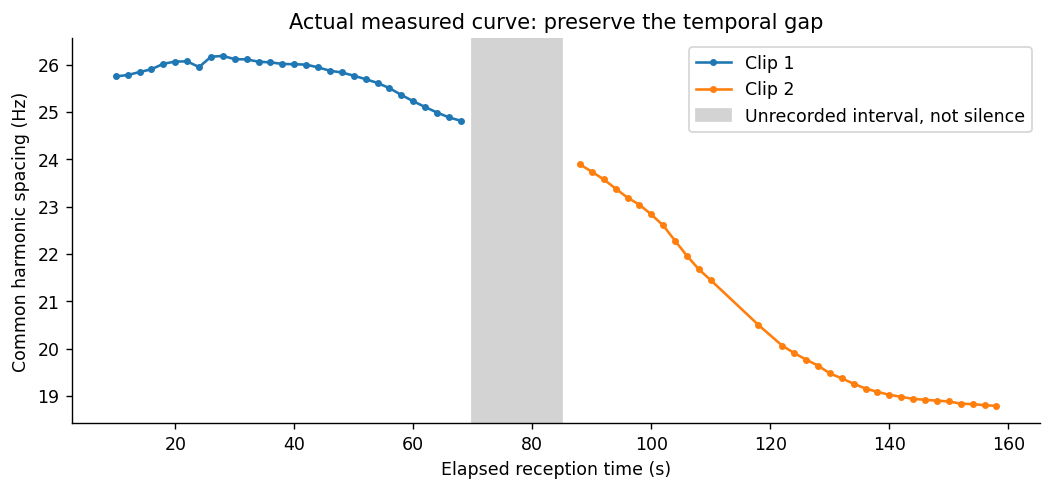

In [2]:
curve = csv_input('measured_curve.csv')
assert len(curve)==62
assert curve.elapsed_s.is_monotonic_increasing
display(curve.head())
display(curve.groupby('clip_index').agg(n=('elapsed_s','size'), start_s=('elapsed_s','min'), end_s=('elapsed_s','max')))
fig, ax = plt.subplots(figsize=(10,4))
for clip,q in curve.groupby('clip_index'):
    ax.plot(q.elapsed_s,q.common_spacing_hz,'o-',ms=3,label=f'Clip {clip}')
ax.axvspan(69.84,85,color='lightgray',label='Unrecorded interval, not silence')
ax.set(xlabel='Elapsed reception time (s)',ylabel='Common harmonic spacing (Hz)',title='Actual measured curve: preserve the temporal gap')
ax.legend(); plt.show()

## 2. Search logic: from sound to aircraft and observer candidates

Capture time and measured sound constrain the search; aircraft and observer position are unknowns in the fitting code. Supplied identity and coordinates are excluded as priors. Four top-200 lists (two models × two objectives) yield a union of 361 candidates. Coverage differs by model: 359 are covered in either, 357 in both, and 358 are ranked per model.

The spatial-grid lane is **schematic**, not a map or a confidence region. A retained alternative spatial basin means the numerical winner is not a uniquely proven location. Reference information was already known to investigators; the final comparison is retrospective, not blind.

**Marker key:** stars in the manuscript and notebook candidate plots identify **A-27: supplied reference aircraft**. They are not estimated observer locations, significance marks or confidence statements.

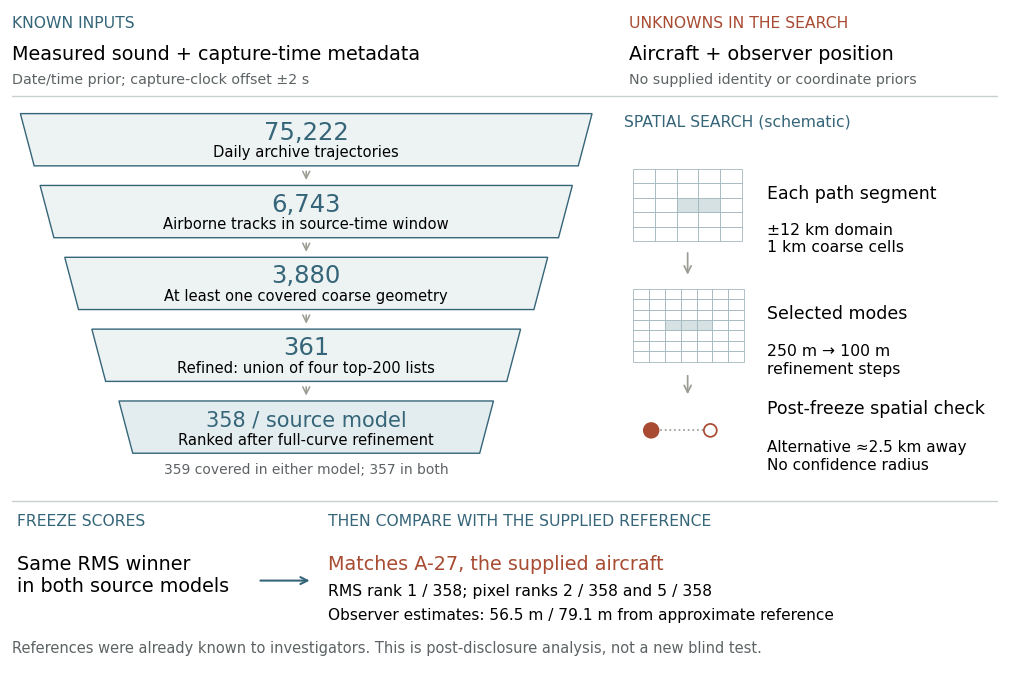

In [3]:
from matplotlib.patches import Polygon, Rectangle
S=json.loads(INPUTS['corrected_search_summary.json'])
blue='#356579';red='#A84B32';grey='#9c9c94';ink='#252c30';pale='#EDF2F2'
# Funnel and spatial lane: every count is read from the preserved public summary.
fig=plt.figure(figsize=(8.3,5.5));ax=fig.add_axes([.025,.02,.95,.95]);ax.set(xlim=(0,10),ylim=(0,10));ax.axis('off')
ax.text(0,9.95,'KNOWN INPUTS',fontsize=9,color=blue,va='top');ax.text(0,9.5,'Measured sound + capture-time metadata',fontsize=11,va='top')
ax.text(0,9.08,'Date/time prior; capture-clock offset ±2 s',fontsize=8.2,color='#5d6365',va='top')
ax.text(6.25,9.95,'UNKNOWNS IN THE SEARCH',fontsize=9,color=red,va='top');ax.text(6.25,9.5,'Aircraft + observer position',fontsize=11,va='top');ax.text(6.25,9.08,'No supplied identity or coordinate priors',fontsize=8.2,color='#5d6365',va='top')
ax.plot([0,10],[8.72,8.72],color='#c9d0d1',lw=.8)
rows=[(f"{S['archive_files']:,}",'Daily archive trajectories'),(f"{S['coarse_aircraft']:,}",'Airborne tracks in source-time window'),(f"{S['coarse_covered_aircraft']:,}",'At least one covered coarse geometry'),(f"{S['selected_for_refinement']:,}",'Refined: union of four top-200 lists'),('358 / source model','Ranked after full-curve refinement')]
widths=[5.8,5.4,4.9,4.35,3.8];ys=[8.05,6.95,5.85,4.75,3.65]
for i,((count,lab),width,y)in enumerate(zip(rows,widths,ys)):
 center=2.98;x0=center-width/2;x1=center+width/2;bottom=width-.28;ax.add_patch(Polygon([[x0,y+.4],[x1,y+.4],[center+bottom/2,y-.4],[center-bottom/2,y-.4]],closed=True,facecolor=pale if i<4 else '#E3ECEE',edgecolor=blue,lw=.8));ax.text(center,y+.11,count,ha='center',va='center',fontsize=14 if i<4 else 12,color=blue);ax.text(center,y-.20,lab,ha='center',va='center',fontsize=8.5)
 if i<4:ax.annotate('',xy=(center,y-.67),xytext=(center,y-.43),arrowprops={'arrowstyle':'->','color':grey,'lw':.9})
ax.text(2.98,2.93,'359 covered in either model; 357 in both',ha='center',fontsize=8,color='#5d6365')
# Nongeographic grid illustrations explain spatial refinement, not empirical posteriors.
ax.text(6.2,8.25,'SPATIAL SEARCH (schematic)',fontsize=9,color=blue)
def grid(x,y,cell,n,marked):
 for i in range(n):
  for j in range(n):ax.add_patch(Rectangle((x+i*cell,y+j*cell),cell,cell,facecolor='#D6E1E4'if(i,j)in marked else'white',edgecolor='#9eb4bb',lw=.45))
grid(6.3,6.5,.22,5,[(2,2),(3,2)]);ax.text(7.65,7.15,'Each path segment',fontsize=10);ax.text(7.65,6.78,'±12 km domain\n1 km coarse cells',fontsize=9,va='top');ax.annotate('',xy=(6.85,5.93),xytext=(6.85,6.37),arrowprops={'arrowstyle':'->','color':grey})
grid(6.3,4.65,.16,7,[(2,3),(3,3),(4,3)]);ax.text(7.65,5.3,'Selected modes',fontsize=10);ax.text(7.65,4.92,'250 m → 100 m\nrefinement steps',fontsize=9,va='top');ax.annotate('',xy=(6.85,4.1),xytext=(6.85,4.49),arrowprops={'arrowstyle':'->','color':grey})
ax.scatter([6.48,7.08],[3.60,3.60],s=[72,55],facecolor=[red,'white'],edgecolor=red,zorder=4);ax.plot([6.48,7.08],[3.6,3.6],color=grey,ls=':',lw=1);ax.text(7.65,3.85,'Post-freeze spatial check',fontsize=10);ax.text(7.65,3.45,'Alternative ≈2.5 km away\nNo confidence radius',fontsize=8.8,va='top')
ax.plot([0,10],[2.52,2.52],color='#c9d0d1',lw=.8)
ax.text(.05,2.14,'FREEZE SCORES',fontsize=9,color=blue);ax.text(3.2,2.14,'THEN COMPARE WITH THE SUPPLIED REFERENCE',fontsize=9,color=blue)
ax.text(.05,1.69,'Same RMS winner\nin both source models',fontsize=11,va='top');ax.annotate('',xy=(3.05,1.30),xytext=(2.48,1.30),arrowprops={'arrowstyle':'->','color':blue,'lw':1.2})
ax.text(3.2,1.69,'Matches A-27, the supplied aircraft',fontsize=11,va='top',color=red);ax.text(3.2,1.25,'RMS rank 1 / 358; pixel ranks 2 / 358 and 5 / 358',fontsize=9,va='top');ax.text(3.2,.88,'Observer estimates: 56.5 m / 79.1 m from approximate reference',fontsize=8.9,va='top')
ax.text(0,.20,'References were already known to investigators. This is post-disclosure analysis, not a new blind test.',fontsize=8.4,color='#5d6365')

plt.show()

## 3. Why does the leading candidate score better?

The figure compares actual **frozen predicted curves**, not illustrative fits. Each aircraft uses its own best retained observer position, clock offset and source-pitch parameters. Every score uses the same 62 measured blocks; missing audio remains a gap. The embedded table has 620 rows: five candidates × two models × 62 blocks.

Bars show the five lowest curve-RMS scores; curves and residuals show the top three. The same aircraft leads both models. Its advantage over the runner-up is approximately **0.0131 Hz / 0.0205 Hz**, which is a small numerical margin, not an identification probability or a decisive exclusion of alternatives. Spectral-objective ranks remain second and fifth. A-27 denotes the supplied reference aircraft, not a blind identification.

The checks below independently recompute all ten RMS scores from the retained residuals. They verify the score arithmetic, not the original optimization or a global uniqueness claim.

All ten retained RMS values independently recomputed from 62 residuals each.


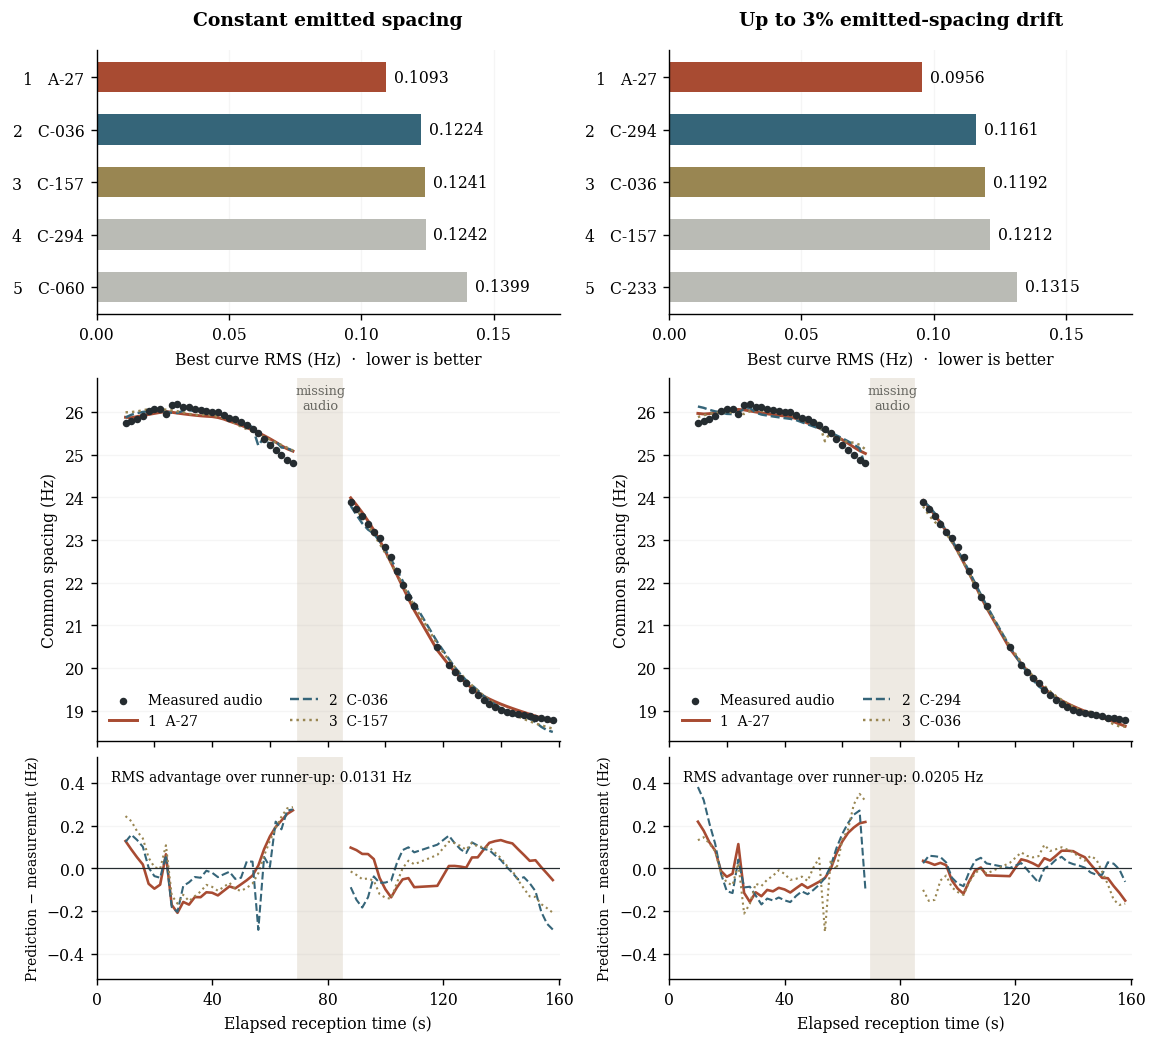

In [4]:
INPUTS['top_candidate_prediction_comparison.csv'] = 'source_model,rank,label,elapsed_s,clip_index,measured_spacing_hz,predicted_spacing_hz,residual_hz,candidate_rms_hz\nconstant,1,A-27,10.0,1,25.75009489085843,25.877284278072963,0.127189387214532,0.10932475637758012\nconstant,1,A-27,12.0,1,25.779135235802563,25.867071203712413,0.08793596790984992,0.10932475637758012\nconstant,1,A-27,14.0,1,25.84211877029926,25.89326350050321,0.05114473020395138,0.10932475637758012\nconstant,1,A-27,16.0,1,25.901941690668064,25.91952381923098,0.01758212856291763,0.10932475637758012\nconstant,1,A-27,18.0,1,26.017165091586392,25.94449242941578,-0.07267266217061064,0.10932475637758012\nconstant,1,A-27,20.0,1,26.0638901086445,25.968313555835497,-0.09557655280900335,0.10932475637758012\nconstant,1,A-27,22.0,1,26.06792022099762,25.99115062565424,-0.07676959534338224,0.10932475637758012\nconstant,1,A-27,24.0,1,25.947684528439588,26.013151894682075,0.06546736624248695,0.10932475637758012\nconstant,1,A-27,26.0,1,26.16587195605319,25.994400697848093,-0.17147125820509856,0.10932475637758012\nconstant,1,A-27,28.0,1,26.183595209725528,25.975065598111648,-0.20852961161387995,0.10932475637758012\nconstant,1,A-27,30.0,1,26.114508816540987,25.956977005575443,-0.15753181096554414,0.10932475637758012\nconstant,1,A-27,32.0,1,26.110482541705075,25.940294132912985,-0.17018840879208952,0.10932475637758012\nconstant,1,A-27,34.0,1,26.060026102845505,25.925209266051027,-0.13481683679447798,0.10932475637758012\nconstant,1,A-27,36.0,1,26.04745953887253,25.91194097190988,-0.1355185669626522,0.10932475637758012\nconstant,1,A-27,38.0,1,26.01347078531878,25.901103764046205,-0.11236702127257558,0.10932475637758012\nconstant,1,A-27,40.0,1,26.00796705698541,25.893360734957003,-0.1146063220284077,0.10932475637758012\nconstant,1,A-27,42.0,1,25.99896261052233,25.87192027611557,-0.1270423344067595,0.10932475637758012\nconstant,1,A-27,44.0,1,25.94155079732816,25.835794361457772,-0.10575643587038641,0.10932475637758012\nconstant,1,A-27,46.0,1,25.86955184075515,25.784798079800826,-0.08475376095432452,0.10932475637758012\nconstant,1,A-27,48.0,1,25.833418753642924,25.73932683633,-0.0940919173129231,0.10932475637758012\nconstant,1,A-27,50.0,1,25.765095558059315,25.689798833054006,-0.07529672500530893,0.10932475637758012\nconstant,1,A-27,52.0,1,25.692059557647468,25.63603480769114,-0.05602474995632889,0.10932475637758012\nconstant,1,A-27,54.0,1,25.61188799670996,25.57783810971731,-0.034049886992651324,0.10932475637758012\nconstant,1,A-27,56.0,1,25.50226981892492,25.514993282517548,0.012723463592628548,0.10932475637758012\nconstant,1,A-27,58.0,1,25.357986352793663,25.447264836374046,0.08927848358038304,0.10932475637758012\nconstant,1,A-27,60.0,1,25.22570890581611,25.374396353486954,0.14868744767084507,0.10932475637758012\nconstant,1,A-27,62.0,1,25.103285266701537,25.296110115236985,0.192824848535448,0.10932475637758012\nconstant,1,A-27,64.0,1,24.986591450063408,25.209627704446532,0.2230362543831248,0.10932475637758012\nconstant,1,A-27,66.0,1,24.884488946021264,25.138473971710376,0.2539850256891114,0.10932475637758012\nconstant,1,A-27,68.0,1,24.812082517201823,25.083280126842215,0.2711976096403923,0.10932475637758012\nconstant,1,A-27,88.0,2,23.892428179445005,23.988930294452658,0.09650211500765238,0.10932475637758012\nconstant,1,A-27,90.0,2,23.73679009173261,23.821508551233492,0.08471845950088408,0.10932475637758012\nconstant,1,A-27,92.0,2,23.57543391158625,23.64247329271504,0.06703938112879015,0.10932475637758012\nconstant,1,A-27,94.0,2,23.381005712161933,23.447506146295115,0.0665004341331823,0.10932475637758012\nconstant,1,A-27,96.0,2,23.18988640861931,23.23266923857606,0.04278282995675298,0.10932475637758012\nconstant,1,A-27,98.0,2,23.040009970669573,22.99474829677584,-0.0452616738937337,0.10932475637758012\nconstant,1,A-27,100.0,2,22.834449703546504,22.73629775274632,-0.09815195080018313,0.10932475637758012\nconstant,1,A-27,102.0,2,22.601643857563893,22.4656223940116,-0.13602146355229294,0.10932475637758012\nconstant,1,A-27,104.0,2,22.27692060885615,22.187218144780367,-0.08970246407578486,0.10932475637758012\nconstant,1,A-27,106.0,2,21.95806357985853,21.906162234494083,-0.05190134536444546,0.10932475637758012\nconstant,1,A-27,108.0,2,21.673753166585577,21.627648021577194,-0.04610514500838292,0.10932475637758012\nconstant,1,A-27,110.0,2,21.445037619345683,21.356554192964676,-0.08848342638100704,0.10932475637758012\nconstant,1,A-27,118.0,2,20.50005321354645,20.417858414219378,-0.0821947993270733,0.10932475637758012\nconstant,1,A-27,122.0,2,20.06221643722642,20.07278916557966,0.010572728353238858,0.10932475637758012\nconstant,1,A-27,124.0,2,19.90695596431901,19.917810764539187,0.010854800220176486,0.10932475637758012\nconstant,1,A-27,126.0,2,19.767451384323167,19.775273286103126,0.007821901779959006,0.10932475637758012\nconstant,1,A-27,128.0,2,19.642433693200232,19.64517480937917,0.002741116178938796,0.10932475637758012\nconstant,1,A-27,130.0,2,19.47666220765512,19.527199611540123,0.05053740388500216,0.10932475637758012\nconstant,1,A-27,132.0,2,19.37150301464768,19.422545814708386,0.051042800060706384,0.10932475637758012\nconstant,1,A-27,134.0,2,19.257890057008147,19.344500363557,0.08661030654885238,0.10932475637758012\nconstant,1,A-27,136.0,2,19.15613419136956,19.275113027181472,0.11897883581191238,0.10932475637758012\nconstant,1,A-27,138.0,2,19.08588648629184,19.212706430033098,0.12681994374125694,0.10932475637758012\nconstant,1,A-27,140.0,2,19.024117723485663,19.15585611640881,0.13173839292314682,0.10932475637758012\nconstant,1,A-27,142.0,2,18.98060932202732,19.103354532472814,0.12274521044549402,0.10932475637758012\nconstant,1,A-27,144.0,2,18.93791383289813,19.054178699937623,0.11626486703949368,0.10932475637758012\nconstant,1,A-27,146.0,2,18.91878708638682,19.007461984814068,0.08867489842724652,0.10932475637758012\nconstant,1,A-27,148.0,2,18.900144863680737,18.962469884586845,0.062325020906108364,0.10932475637758012\nconstant,1,A-27,150.0,2,18.883798750423363,18.91857951245767,0.03478076203430547,0.10932475637758012\nconstant,1,A-27,152.0,2,18.837697490207336,18.87526235455884,0.03756486435150208,0.10932475637758012\nconstant,1,A-27,154.0,2,18.82698599175444,18.832069854043564,0.00508386228912272,0.10932475637758012\nconstant,1,A-27,156.0,2,18.805204826921933,18.780560950833344,-0.024643876088589423,0.10932475637758012\nconstant,1,A-27,158.0,2,18.78951166472781,18.73423984362333,-0.05527182110447981,0.10932475637758012\nconstant,2,C-036,10.0,1,25.75009489085843,25.87339769406557,0.12330280320713882,0.12243451105238809\nconstant,2,C-036,12.0,1,25.779135235802563,25.936109445120877,0.15697420931831374,0.12243451105238809\nconstant,2,C-036,14.0,1,25.84211877029926,25.974420799599365,0.13230202930010648,0.12243451105238809\nconstant,2,C-036,16.0,1,25.901941690668064,26.002450685979483,0.10050899531141866,0.12243451105238809\nconstant,2,C-036,18.0,1,26.017165091586392,26.020035903455433,0.0028708118690410345,0.12243451105238809\nconstant,2,C-036,20.0,1,26.0638901086445,26.027065068903152,-0.03682503974134832,0.12243451105238809\nconstant,2,C-036,22.0,1,26.06792022099762,26.02347180621038,-0.044448414787240154,0.12243451105238809\nconstant,2,C-036,24.0,1,25.947684528439588,26.009226081452457,0.06154155301286934,0.12243451105238809\nconstant,2,C-036,26.0,1,26.16587195605319,25.9843237570962,-0.18154819895699248,0.12243451105238809\nconstant,2,C-036,28.0,1,26.183595209725528,25.979588627406365,-0.20400658231916324,0.12243451105238809\nconstant,2,C-036,30.0,1,26.114508816540987,26.031648943299928,-0.08285987324105903,0.12243451105238809\nconstant,2,C-036,32.0,1,26.110482541705075,26.0447204464267,-0.06576209527837307,0.12243451105238809\nconstant,2,C-036,34.0,1,26.060026102845505,26.019063287389464,-0.04096281545604086,0.12243451105238809\nconstant,2,C-036,36.0,1,26.04745953887253,26.002893090429126,-0.04456644844340474,0.12243451105238809\nconstant,2,C-036,38.0,1,26.01347078531878,26.00192550720359,-0.011545278115189461,0.12243451105238809\nconstant,2,C-036,40.0,1,26.00796705698541,25.986978261490464,-0.020988795494947254,0.12243451105238809\nconstant,2,C-036,42.0,1,25.99896261052233,25.957541495070274,-0.04142111545205651,0.12243451105238809\nconstant,2,C-036,44.0,1,25.94155079732816,25.913110128577184,-0.028440668750974396,0.12243451105238809\nconstant,2,C-036,46.0,1,25.86955184075515,25.853175246892707,-0.016376593862442945,0.12243451105238809\nconstant,2,C-036,48.0,1,25.833418753642924,25.783603874961226,-0.04981487868169765,0.12243451105238809\nconstant,2,C-036,50.0,1,25.765095558059315,25.720572680706276,-0.04452287735303884,0.12243451105238809\nconstant,2,C-036,52.0,1,25.692059557647468,25.72407712447029,0.032017566822823085,0.12243451105238809\nconstant,2,C-036,54.0,1,25.61188799670996,25.64281213284187,0.030924136131908142,0.12243451105238809\nconstant,2,C-036,56.0,1,25.50226981892492,25.214061367906783,-0.28820845101813575,0.12243451105238809\nconstant,2,C-036,58.0,1,25.357986352793663,25.410846350779906,0.052859997986242746,0.12243451105238809\nconstant,2,C-036,60.0,1,25.22570890581611,25.231637827792532,0.0059289219764231404,0.12243451105238809\nconstant,2,C-036,62.0,1,25.103285266701537,25.321388845294326,0.21810357859278895,0.12243451105238809\nconstant,2,C-036,64.0,1,24.986591450063408,25.16871798662877,0.18212653656536304,0.12243451105238809\nconstant,2,C-036,66.0,1,24.884488946021264,25.154669281838956,0.27018033581769174,0.12243451105238809\nconstant,2,C-036,68.0,1,24.812082517201823,25.08739188853271,0.27530937133088784,0.12243451105238809\nconstant,2,C-036,88.0,2,23.892428179445005,23.803599404246395,-0.08882877519861054,0.12243451105238809\nconstant,2,C-036,90.0,2,23.73679009173261,23.58886837752389,-0.14792171420871725,0.12243451105238809\nconstant,2,C-036,92.0,2,23.57543391158625,23.391626125410813,-0.1838077861754357,0.12243451105238809\nconstant,2,C-036,94.0,2,23.381005712161933,23.2452939930082,-0.1357117191537327,0.12243451105238809\nconstant,2,C-036,96.0,2,23.18988640861931,23.151720603513755,-0.03816580510555312,0.12243451105238809\nconstant,2,C-036,98.0,2,23.040009970669573,22.971649853989852,-0.0683601166797203,0.12243451105238809\nconstant,2,C-036,100.0,2,22.834449703546504,22.76751725887884,-0.06693244466766402,0.12243451105238809\nconstant,2,C-036,102.0,2,22.601643857563893,22.54357492166075,-0.05806893590314388,0.12243451105238809\nconstant,2,C-036,104.0,2,22.27692060885615,22.301344638452555,0.02442402959640333,0.12243451105238809\nconstant,2,C-036,106.0,2,21.95806357985853,22.043114243779392,0.08505066392086391,0.12243451105238809\nconstant,2,C-036,108.0,2,21.673753166585577,21.771852817604966,0.098099651019389,0.12243451105238809\nconstant,2,C-036,110.0,2,21.445037619345683,21.519418567521292,0.07438094817560881,0.12243451105238809\nconstant,2,C-036,118.0,2,20.50005321354645,20.610308081718564,0.11025486817211316,0.12243451105238809\nconstant,2,C-036,122.0,2,20.06221643722642,20.21478852912846,0.15257209190203724,0.12243451105238809\nconstant,2,C-036,124.0,2,19.90695596431901,20.02456832993861,0.11761236561959976,0.12243451105238809\nconstant,2,C-036,126.0,2,19.767451384323167,19.856488726683853,0.08903734236068672,0.12243451105238809\nconstant,2,C-036,128.0,2,19.642433693200232,19.71351746610376,0.07108377290352763,0.12243451105238809\nconstant,2,C-036,130.0,2,19.47666220765512,19.597739614185038,0.12107740652991694,0.12243451105238809\nconstant,2,C-036,132.0,2,19.37150301464768,19.477582047002485,0.1060790323548062,0.12243451105238809\nconstant,2,C-036,134.0,2,19.257890057008147,19.348197008813777,0.09030695180562986,0.12243451105238809\nconstant,2,C-036,136.0,2,19.15613419136956,19.240789272654602,0.0846550812850424,0.12243451105238809\nconstant,2,C-036,138.0,2,19.08588648629184,19.146488417463377,0.06060193117153645,0.12243451105238809\nconstant,2,C-036,140.0,2,19.024117723485663,19.062573577004553,0.03845585351889014,0.12243451105238809\nconstant,2,C-036,142.0,2,18.98060932202732,18.986718601853095,0.00610927982577536,0.12243451105238809\nconstant,2,C-036,144.0,2,18.93791383289813,18.916931935548313,-0.02098189734981659,0.12243451105238809\nconstant,2,C-036,146.0,2,18.91878708638682,18.86619759301888,-0.05258949336793961,0.12243451105238809\nconstant,2,C-036,148.0,2,18.900144863680737,18.858443059750428,-0.041701803930308756,0.12243451105238809\nconstant,2,C-036,150.0,2,18.883798750423363,18.813783825023815,-0.07001492539954768,0.12243451105238809\nconstant,2,C-036,152.0,2,18.837697490207336,18.730484737760953,-0.10721275244638306,0.12243451105238809\nconstant,2,C-036,154.0,2,18.82698599175444,18.623187345557472,-0.20379864619696875,0.12243451105238809\nconstant,2,C-036,156.0,2,18.805204826921933,18.54548115254455,-0.2597236743773834,0.12243451105238809\nconstant,2,C-036,158.0,2,18.78951166472781,18.502805740418133,-0.286705924309679,0.12243451105238809\nconstant,3,C-157,10.0,1,25.75009489085843,25.993994513554153,0.24389962269572152,0.12413839064467717\nconstant,3,C-157,12.0,1,25.779135235802563,25.999477554706676,0.2203423189041125,0.12413839064467717\nconstant,3,C-157,14.0,1,25.84211877029926,26.015350639294855,0.17323186899559673,0.12413839064467717\nconstant,3,C-157,16.0,1,25.901941690668064,26.04159841208732,0.13965672141925722,0.12413839064467717\nconstant,3,C-157,18.0,1,26.017165091586392,26.066515788562178,0.04935069697578598,0.12413839064467717\nconstant,3,C-157,20.0,1,26.0638901086445,26.068877326174935,0.004987217530434407,0.12413839064467717\nconstant,3,C-157,22.0,1,26.06792022099762,26.065162361773968,-0.002757859223653014,0.12413839064467717\nconstant,3,C-157,24.0,1,25.947684528439588,26.05539211130268,0.10770758286309245,0.12413839064467717\nconstant,3,C-157,26.0,1,26.16587195605319,26.03960996402277,-0.12626199203042177,0.12413839064467717\nconstant,3,C-157,28.0,1,26.183595209725528,26.01788130015479,-0.16571390957073717,0.12413839064467717\nconstant,3,C-157,30.0,1,26.114508816540987,25.990293116872643,-0.12421569966834412,0.12413839064467717\nconstant,3,C-157,32.0,1,26.110482541705075,25.956953457520523,-0.15352908418455158,0.12413839064467717\nconstant,3,C-157,34.0,1,26.060026102845505,25.929437707538266,-0.13058839530723887,0.12413839064467717\nconstant,3,C-157,36.0,1,26.04745953887253,25.938490594696695,-0.10896894417583525,0.12413839064467717\nconstant,3,C-157,38.0,1,26.01347078531878,25.935717186885682,-0.07775359843309815,0.12413839064467717\nconstant,3,C-157,40.0,1,26.00796705698541,25.920843072280014,-0.0871239847053964,0.12413839064467717\nconstant,3,C-157,42.0,1,25.99896261052233,25.893628361628796,-0.10533424889353427,0.12413839064467717\nconstant,3,C-157,44.0,1,25.94155079732816,25.853869107884865,-0.08768168944329346,0.12413839064467717\nconstant,3,C-157,46.0,1,25.86955184075515,25.801398874622713,-0.0681529661324376,0.12413839064467717\nconstant,3,C-157,48.0,1,25.833418753642924,25.736090620983433,-0.09732813265949147,0.12413839064467717\nconstant,3,C-157,50.0,1,25.765095558059315,25.659151431455573,-0.10594412660374175,0.12413839064467717\nconstant,3,C-157,52.0,1,25.692059557647468,25.60052674532525,-0.09153281232221744,0.12413839064467717\nconstant,3,C-157,54.0,1,25.61188799670996,25.540460248420846,-0.07142774828911413,0.12413839064467717\nconstant,3,C-157,56.0,1,25.50226981892492,25.47917367843647,-0.023096140488448214,0.12413839064467717\nconstant,3,C-157,58.0,1,25.357986352793663,25.41693465101998,0.05894829822631564,0.12413839064467717\nconstant,3,C-157,60.0,1,25.22570890581611,25.354052179258655,0.12834327344254604,0.12413839064467717\nconstant,3,C-157,62.0,1,25.103285266701537,25.290871550638737,0.18758628393720045,0.12413839064467717\nconstant,3,C-157,64.0,1,24.986591450063408,25.227768511419473,0.24117706135606554,0.12413839064467717\nconstant,3,C-157,66.0,1,24.884488946021264,25.165142693226255,0.28065374720499037,0.12413839064467717\nconstant,3,C-157,68.0,1,24.812082517201823,25.09808389514278,0.2860013779409556,0.12413839064467717\nconstant,3,C-157,88.0,2,23.892428179445005,23.877514951982416,-0.014913227462589163,0.12413839064467717\nconstant,3,C-157,90.0,2,23.73679009173261,23.705656878667654,-0.031133213064954646,0.12413839064467717\nconstant,3,C-157,92.0,2,23.57543391158625,23.52439384107962,-0.051040070506630286,0.12413839064467717\nconstant,3,C-157,94.0,2,23.381005712161933,23.333070673785546,-0.04793503837638724,0.12413839064467717\nconstant,3,C-157,96.0,2,23.18988640861931,23.131301913034793,-0.058584495584515395,0.12413839064467717\nconstant,3,C-157,98.0,2,23.040009970669573,22.91903702721549,-0.12097294345408116,0.12413839064467717\nconstant,3,C-157,100.0,2,22.834449703546504,22.696615811130776,-0.13783389241572763,0.12413839064467717\nconstant,3,C-157,102.0,2,22.601643857563893,22.45877167455842,-0.14287218300547266,0.12413839064467717\nconstant,3,C-157,104.0,2,22.27692060885615,22.20907950677349,-0.06784110208266014,0.12413839064467717\nconstant,3,C-157,106.0,2,21.95806357985853,21.958340647768857,0.0002770679103285545,0.12413839064467717\nconstant,3,C-157,108.0,2,21.673753166585577,21.709069609248488,0.035316442662910674,0.12413839064467717\nconstant,3,C-157,110.0,2,21.445037619345683,21.46372324533553,0.018685625989846244,0.12413839064467717\nconstant,3,C-157,118.0,2,20.50005321354645,20.562383256500176,0.06233004295372524,0.12413839064467717\nconstant,3,C-157,122.0,2,20.06221643722642,20.186259653465445,0.12404321623902348,0.12413839064467717\nconstant,3,C-157,124.0,2,19.90695596431901,20.02454946270676,0.11759349838774824,0.12413839064467717\nconstant,3,C-157,126.0,2,19.767451384323167,19.87186462911029,0.10441324478712488,0.12413839064467717\nconstant,3,C-157,128.0,2,19.642433693200232,19.728724939914116,0.0862912467138841,0.12413839064467717\nconstant,3,C-157,130.0,2,19.47666220765512,19.595391212464268,0.11872900480914694,0.12413839064467717\nconstant,3,C-157,132.0,2,19.37150301464768,19.471909580857854,0.10040656621017519,0.12413839064467717\nconstant,3,C-157,134.0,2,19.257890057008147,19.358155852441115,0.10026579543296776,0.12413839064467717\nconstant,3,C-157,136.0,2,19.15613419136956,19.253876794524473,0.0977426031549129,0.12413839064467717\nconstant,3,C-157,138.0,2,19.08588648629184,19.158726493483957,0.07284000719211647,0.12413839064467717\nconstant,3,C-157,140.0,2,19.024117723485663,19.072296961886998,0.04817923840133531,0.12413839064467717\nconstant,3,C-157,142.0,2,18.98060932202732,18.994142912758374,0.01353359073105409,0.12413839064467717\nconstant,3,C-157,144.0,2,18.93791383289813,18.92545587037616,-0.012457962521967403,0.12413839064467717\nconstant,3,C-157,146.0,2,18.91878708638682,18.86278615647826,-0.05600092990855998,0.12413839064467717\nconstant,3,C-157,148.0,2,18.900144863680737,18.805105586478142,-0.09503927720259497,0.12413839064467717\nconstant,3,C-157,150.0,2,18.883798750423363,18.75211061214462,-0.1316881382787436,0.12413839064467717\nconstant,3,C-157,152.0,2,18.837697490207336,18.703513022114794,-0.13418446809254192,0.12413839064467717\nconstant,3,C-157,154.0,2,18.82698599175444,18.659041336864128,-0.16794465489031296,0.12413839064467717\nconstant,3,C-157,156.0,2,18.805204826921933,18.618441424799155,-0.18676340212277864,0.12413839064467717\nconstant,3,C-157,158.0,2,18.78951166472781,18.581476543391272,-0.20803512133653967,0.12413839064467717\nconstant,4,C-294,10.0,1,25.75009489085843,26.025878659172335,0.2757837683139037,0.12422710936458163\nconstant,4,C-294,12.0,1,25.779135235802563,26.026439138108568,0.24730390230600463,0.12422710936458163\nconstant,4,C-294,14.0,1,25.84211877029926,25.98075400831596,0.1386352380167004,0.12422710936458163\nconstant,4,C-294,16.0,1,25.901941690668064,25.947046906822123,0.04510521615405949,0.12422710936458163\nconstant,4,C-294,18.0,1,26.017165091586392,25.925004040449267,-0.09216105113712558,0.12422710936458163\nconstant,4,C-294,20.0,1,26.0638901086445,25.899461714088574,-0.16442839455592662,0.12422710936458163\nconstant,4,C-294,22.0,1,26.06792022099762,25.8874351511333,-0.18048506986432145,0.12422710936458163\nconstant,4,C-294,24.0,1,25.947684528439588,25.91716324892921,-0.030521279510377752,0.12422710936458163\nconstant,4,C-294,26.0,1,26.16587195605319,25.99451544421571,-0.17135651183748024,0.12422710936458163\nconstant,4,C-294,28.0,1,26.183595209725528,26.05822413344753,-0.1253710762779967,0.12422710936458163\nconstant,4,C-294,30.0,1,26.114508816540987,25.990651573024422,-0.12385724351656435,0.12422710936458163\nconstant,4,C-294,32.0,1,26.110482541705075,25.911543615371283,-0.19893892633379195,0.12422710936458163\nconstant,4,C-294,34.0,1,26.060026102845505,25.8931841679024,-0.16684193494310406,0.12422710936458163\nconstant,4,C-294,36.0,1,26.04745953887253,25.876175330137517,-0.17128420873501327,0.12422710936458163\nconstant,4,C-294,38.0,1,26.01347078531878,25.860503620661543,-0.15296716465723748,0.12422710936458163\nconstant,4,C-294,40.0,1,26.00796705698541,25.846152352362537,-0.1618147046228735,0.12422710936458163\nconstant,4,C-294,42.0,1,25.99896261052233,25.833100449255014,-0.16586216126731657,0.12422710936458163\nconstant,4,C-294,44.0,1,25.94155079732816,25.81887417184613,-0.12267662548202907,0.12422710936458163\nconstant,4,C-294,46.0,1,25.86955184075515,25.772693326806756,-0.09685851394839418,0.12422710936458163\nconstant,4,C-294,48.0,1,25.833418753642924,25.727726423519083,-0.1056923301238406,0.12422710936458163\nconstant,4,C-294,50.0,1,25.765095558059315,25.683489038248933,-0.08160651981038214,0.12422710936458163\nconstant,4,C-294,52.0,1,25.692059557647468,25.63943590100916,-0.052623656638306926,0.12422710936458163\nconstant,4,C-294,54.0,1,25.61188799670996,25.59494941794808,-0.016938578761880763,0.12422710936458163\nconstant,4,C-294,56.0,1,25.50226981892492,25.548056774443655,0.045786955518735795,0.12422710936458163\nconstant,4,C-294,58.0,1,25.357986352793663,25.493262775426775,0.1352764226331118,0.12422710936458163\nconstant,4,C-294,60.0,1,25.22570890581611,25.432323270119053,0.20661436430294344,0.12422710936458163\nconstant,4,C-294,62.0,1,25.103285266701537,25.365227970149295,0.26194270344775816,0.12422710936458163\nconstant,4,C-294,64.0,1,24.986591450063408,25.292021577158398,0.30543012709498996,0.12422710936458163\nconstant,4,C-294,66.0,1,24.884488946021264,25.2127881806792,0.328299234657937,0.12422710936458163\nconstant,4,C-294,68.0,1,24.812082517201823,24.87589640318334,0.06381388598151716,0.12422710936458163\nconstant,4,C-294,88.0,2,23.892428179445005,23.96246250392247,0.07003432447746505,0.12422710936458163\nconstant,4,C-294,90.0,2,23.73679009173261,23.81682855668321,0.08003846495060074,0.12422710936458163\nconstant,4,C-294,92.0,2,23.57543391158625,23.650638072083268,0.0752041604970195,0.12422710936458163\nconstant,4,C-294,94.0,2,23.381005712161933,23.447588867206456,0.06658315504452261,0.12422710936458163\nconstant,4,C-294,96.0,2,23.18988640861931,23.219321907531242,0.029435498911933422,0.12422710936458163\nconstant,4,C-294,98.0,2,23.040009970669573,22.987577543185605,-0.052432427483967814,0.12422710936458163\nconstant,4,C-294,100.0,2,22.834449703546504,22.744068002713654,-0.09038170083285024,0.12422710936458163\nconstant,4,C-294,102.0,2,22.601643857563893,22.489049731388047,-0.1125941261758463,0.12422710936458163\nconstant,4,C-294,104.0,2,22.27692060885615,22.223577545146966,-0.0533430637091854,0.12422710936458163\nconstant,4,C-294,106.0,2,21.95806357985853,21.949467159780813,-0.00859642007771555,0.12422710936458163\nconstant,4,C-294,108.0,2,21.673753166585577,21.66917514939507,-0.004578017190507211,0.12422710936458163\nconstant,4,C-294,110.0,2,21.445037619345683,21.4064247489952,-0.038612870350483774,0.12422710936458163\nconstant,4,C-294,118.0,2,20.50005321354645,20.449143891982043,-0.05090932156440786,0.12422710936458163\nconstant,4,C-294,122.0,2,20.06221643722642,20.050400014533032,-0.011816422693389228,0.12422710936458163\nconstant,4,C-294,124.0,2,19.90695596431901,19.874534306597575,-0.03242165772143579,0.12422710936458163\nconstant,4,C-294,126.0,2,19.767451384323167,19.714156433928924,-0.05329495039424259,0.12422710936458163\nconstant,4,C-294,128.0,2,19.642433693200232,19.56867340461871,-0.0737602885815214,0.12422710936458163\nconstant,4,C-294,130.0,2,19.47666220765512,19.460356732764538,-0.01630547489058287,0.12422710936458163\nconstant,4,C-294,132.0,2,19.37150301464768,19.38236397340968,0.010860958762002326,0.12422710936458163\nconstant,4,C-294,134.0,2,19.257890057008147,19.307865898922284,0.04997584191413651,0.12422710936458163\nconstant,4,C-294,136.0,2,19.15613419136956,19.232185549005205,0.07605135763564519,0.12422710936458163\nconstant,4,C-294,138.0,2,19.08588648629184,19.149411345982337,0.06352485969049582,0.12422710936458163\nconstant,4,C-294,140.0,2,19.024117723485663,19.077505405123084,0.053387681637421025,0.12422710936458163\nconstant,4,C-294,142.0,2,18.98060932202732,19.027807899186445,0.047198577159125676,0.12422710936458163\nconstant,4,C-294,144.0,2,18.93791383289813,18.9872048431053,0.049291010207170416,0.12422710936458163\nconstant,4,C-294,146.0,2,18.91878708638682,18.94846055126835,0.029673464881529554,0.12422710936458163\nconstant,4,C-294,148.0,2,18.900144863680737,18.92130736266494,0.021162498984203637,0.12422710936458163\nconstant,4,C-294,150.0,2,18.883798750423363,18.906821407309398,0.023022656886034554,0.12422710936458163\nconstant,4,C-294,152.0,2,18.837697490207336,18.91543735894209,0.0777398687347528,0.12422710936458163\nconstant,4,C-294,154.0,2,18.82698599175444,18.924713858996412,0.09772786724197147,0.12422710936458163\nconstant,4,C-294,156.0,2,18.805204826921933,18.90193334183739,0.09672851491545487,0.12422710936458163\nconstant,4,C-294,158.0,2,18.78951166472781,18.848697297927824,0.05918563320001269,0.12422710936458163\nconstant,5,C-060,10.0,1,25.75009489085843,25.968873767468526,0.2187788766100951,0.1398873100481068\nconstant,5,C-060,12.0,1,25.779135235802563,25.989267027156824,0.21013179135426086,0.1398873100481068\nconstant,5,C-060,14.0,1,25.84211877029926,26.00869775316637,0.1665789828671116,0.1398873100481068\nconstant,5,C-060,16.0,1,25.901941690668064,26.027184296448315,0.12524260578025093,0.1398873100481068\nconstant,5,C-060,18.0,1,26.017165091586392,26.012060678692926,-0.0051044128934663036,0.1398873100481068\nconstant,5,C-060,20.0,1,26.0638901086445,25.99385284977079,-0.07003725887371104,0.1398873100481068\nconstant,5,C-060,22.0,1,26.06792022099762,25.977109823520376,-0.09081039747724517,0.1398873100481068\nconstant,5,C-060,24.0,1,25.947684528439588,25.961591414352363,0.013906885912774669,0.1398873100481068\nconstant,5,C-060,26.0,1,26.16587195605319,25.94703437224706,-0.21883758380613116,0.1398873100481068\nconstant,5,C-060,28.0,1,26.183595209725528,25.933147431441267,-0.25044777828426135,0.1398873100481068\nconstant,5,C-060,30.0,1,26.114508816540987,25.91960562974673,-0.19490318679425656,0.1398873100481068\nconstant,5,C-060,32.0,1,26.110482541705075,25.906043789527573,-0.20443875217750218,0.1398873100481068\nconstant,5,C-060,34.0,1,26.060026102845505,25.893808603000874,-0.16621749984463108,0.1398873100481068\nconstant,5,C-060,36.0,1,26.04745953887253,25.897740766299954,-0.1497187725725766,0.1398873100481068\nconstant,5,C-060,38.0,1,26.01347078531878,25.9107600525356,-0.10271073278317999,0.1398873100481068\nconstant,5,C-060,40.0,1,26.00796705698541,25.859752911916573,-0.14821414506883812,0.1398873100481068\nconstant,5,C-060,42.0,1,25.99896261052233,25.811188058577574,-0.18777455194475579,0.1398873100481068\nconstant,5,C-060,44.0,1,25.94155079732816,25.765138688392714,-0.17641210893544468,0.1398873100481068\nconstant,5,C-060,46.0,1,25.86955184075515,25.72170067790868,-0.1478511628464716,0.1398873100481068\nconstant,5,C-060,48.0,1,25.833418753642924,25.680989544874212,-0.15242920876871224,0.1398873100481068\nconstant,5,C-060,50.0,1,25.765095558059315,25.643137065689242,-0.12195849237007295,0.1398873100481068\nconstant,5,C-060,52.0,1,25.692059557647468,25.60828745478512,-0.08377210286234771,0.1398873100481068\nconstant,5,C-060,54.0,1,25.61188799670996,25.576592980814574,-0.03529501589538597,0.1398873100481068\nconstant,5,C-060,56.0,1,25.50226981892492,25.543952770614062,0.041682951689143266,0.1398873100481068\nconstant,5,C-060,58.0,1,25.357986352793663,25.50350139866486,0.14551504587119624,0.1398873100481068\nconstant,5,C-060,60.0,1,25.22570890581611,25.455006905862597,0.22929800004648726,0.1398873100481068\nconstant,5,C-060,62.0,1,25.103285266701537,25.398028759596844,0.2947434928953072,0.1398873100481068\nconstant,5,C-060,64.0,1,24.986591450063408,25.332107881280905,0.3455164312174972,0.1398873100481068\nconstant,5,C-060,66.0,1,24.884488946021264,25.256768614525136,0.3722796685038716,0.1398873100481068\nconstant,5,C-060,68.0,1,24.812082517201823,25.171523051159976,0.35944053395815345,0.1398873100481068\nconstant,5,C-060,88.0,2,23.892428179445005,23.99465355732688,0.1022253778818758,0.1398873100481068\nconstant,5,C-060,90.0,2,23.73679009173261,23.82981932575112,0.0930292340185126,0.1398873100481068\nconstant,5,C-060,92.0,2,23.57543391158625,23.64329172086238,0.06785780927613061,0.1398873100481068\nconstant,5,C-060,94.0,2,23.381005712161933,23.436343699559416,0.055337987397482635,0.1398873100481068\nconstant,5,C-060,96.0,2,23.18988640861931,23.211056596732966,0.021170188113657673,0.1398873100481068\nconstant,5,C-060,98.0,2,23.040009970669573,22.97083573094562,-0.06917423972395298,0.1398873100481068\nconstant,5,C-060,100.0,2,22.834449703546504,22.721005190039914,-0.11344451350658957,0.1398873100481068\nconstant,5,C-060,102.0,2,22.601643857563893,22.463921649894175,-0.137722207669718,0.1398873100481068\nconstant,5,C-060,104.0,2,22.27692060885615,22.202037214909925,-0.07488339394622656,0.1398873100481068\nconstant,5,C-060,106.0,2,21.95806357985853,21.93817887320382,-0.01988470665470743,0.1398873100481068\nconstant,5,C-060,108.0,2,21.673753166585577,21.675343176897016,0.0015900103114390163,0.1398873100481068\nconstant,5,C-060,110.0,2,21.445037619345683,21.41647234386055,-0.02856527548513199,0.1398873100481068\nconstant,5,C-060,118.0,2,20.50005321354645,20.473913147232643,-0.02614006631380761,0.1398873100481068\nconstant,5,C-060,122.0,2,20.06221643722642,20.086160659506525,0.023944222280103844,0.1398873100481068\nconstant,5,C-060,124.0,2,19.90695596431901,19.9174636626229,0.010507698303889867,0.1398873100481068\nconstant,5,C-060,126.0,2,19.767451384323167,19.76557822995362,-0.0018731543695480468,0.1398873100481068\nconstant,5,C-060,128.0,2,19.642433693200232,19.62978230212921,-0.012651391071020868,0.1398873100481068\nconstant,5,C-060,130.0,2,19.47666220765512,19.510788923685745,0.03412671603062378,0.1398873100481068\nconstant,5,C-060,132.0,2,19.37150301464768,19.40367614596563,0.03217313131795052,0.1398873100481068\nconstant,5,C-060,134.0,2,19.257890057008147,19.303310491844627,0.04542043483647973,0.1398873100481068\nconstant,5,C-060,136.0,2,19.15613419136956,19.205564774882248,0.04943058351268803,0.1398873100481068\nconstant,5,C-060,138.0,2,19.08588648629184,19.126878005110047,0.040991518818206174,0.1398873100481068\nconstant,5,C-060,140.0,2,19.024117723485663,19.061323312832982,0.037205589347319545,0.1398873100481068\nconstant,5,C-060,142.0,2,18.98060932202732,19.00756836741617,0.026959045388849745,0.1398873100481068\nconstant,5,C-060,144.0,2,18.93791383289813,18.965801845909308,0.027888013011178714,0.1398873100481068\nconstant,5,C-060,146.0,2,18.91878708638682,18.936106844704586,0.017319758317764666,0.1398873100481068\nconstant,5,C-060,148.0,2,18.900144863680737,18.918495949619277,0.018351085938540734,0.1398873100481068\nconstant,5,C-060,150.0,2,18.883798750423363,18.894342338560254,0.010543588136890492,0.1398873100481068\nconstant,5,C-060,152.0,2,18.837697490207336,18.852667782495878,0.014970292288541742,0.1398873100481068\nconstant,5,C-060,154.0,2,18.82698599175444,18.79623629671092,-0.03074969504352154,0.1398873100481068\nconstant,5,C-060,156.0,2,18.805204826921933,18.724491501863337,-0.0807133250585963,0.1398873100481068\nconstant,5,C-060,158.0,2,18.78951166472781,18.665359625028298,-0.1241520396995135,0.1398873100481068\nbounded_3pct_drift,1,A-27,10.0,1,25.75009489085843,25.967980859081287,0.21788596822285555,0.09559630994519268\nbounded_3pct_drift,1,A-27,12.0,1,25.779135235802563,25.95463315096729,0.17549791516472624,0.09559630994519268\nbounded_3pct_drift,1,A-27,14.0,1,25.84211877029926,25.962938117144322,0.12081934684506379,0.09559630994519268\nbounded_3pct_drift,1,A-27,16.0,1,25.901941690668064,25.98422703041081,0.08228533974274654,0.09559630994519268\nbounded_3pct_drift,1,A-27,18.0,1,26.017165091586392,26.004486038989445,-0.012679052596947571,0.09559630994519268\nbounded_3pct_drift,1,A-27,20.0,1,26.0638901086445,26.023878869583484,-0.04001123906101611,0.09559630994519268\nbounded_3pct_drift,1,A-27,22.0,1,26.06792022099762,26.04260127573081,-0.025318945266811,0.09559630994519268\nbounded_3pct_drift,1,A-27,24.0,1,25.947684528439588,26.060849375321133,0.1131648468815456,0.09559630994519268\nbounded_3pct_drift,1,A-27,26.0,1,26.16587195605319,26.050645530558207,-0.11522642549498485,0.09559630994519268\nbounded_3pct_drift,1,A-27,28.0,1,26.183595209725528,26.025788478672546,-0.15780673105298249,0.09559630994519268\nbounded_3pct_drift,1,A-27,30.0,1,26.114508816540987,26.00208109268331,-0.11242772385767807,0.09559630994519268\nbounded_3pct_drift,1,A-27,32.0,1,26.110482541705075,25.97966185859374,-0.13082068311133455,0.09559630994519268\nbounded_3pct_drift,1,A-27,34.0,1,26.060026102845505,25.958702618317865,-0.10132348452764006,0.09559630994519268\nbounded_3pct_drift,1,A-27,36.0,1,26.04745953887253,25.939401808768896,-0.10805773010363495,0.09559630994519268\nbounded_3pct_drift,1,A-27,38.0,1,26.01347078531878,25.92197667559528,-0.09149410972350225,0.09559630994519268\nbounded_3pct_drift,1,A-27,40.0,1,26.00796705698541,25.908915575915398,-0.09905148107001338,0.09559630994519268\nbounded_3pct_drift,1,A-27,42.0,1,25.99896261052233,25.885512262371723,-0.11345034815060728,0.09559630994519268\nbounded_3pct_drift,1,A-27,44.0,1,25.94155079732816,25.847887745963458,-0.09366305136470032,0.09559630994519268\nbounded_3pct_drift,1,A-27,46.0,1,25.86955184075515,25.79508503852548,-0.07446680222966862,0.09559630994519268\nbounded_3pct_drift,1,A-27,48.0,1,25.833418753642924,25.7412149995478,-0.09220375409512371,0.09559630994519268\nbounded_3pct_drift,1,A-27,50.0,1,25.765095558059315,25.68719764237116,-0.07789791568815474,0.09559630994519268\nbounded_3pct_drift,1,A-27,52.0,1,25.692059557647468,25.62900577765083,-0.06305377999663975,0.09559630994519268\nbounded_3pct_drift,1,A-27,54.0,1,25.61188799670996,25.566458699657627,-0.04542929705233334,0.09559630994519268\nbounded_3pct_drift,1,A-27,56.0,1,25.50226981892492,25.499359778953647,-0.0029100399712724823,0.09559630994519268\nbounded_3pct_drift,1,A-27,58.0,1,25.357986352793663,25.427495665815393,0.06950931302172947,0.09559630994519268\nbounded_3pct_drift,1,A-27,60.0,1,25.22570890581611,25.35063584846044,0.12492694264432913,0.09559630994519268\nbounded_3pct_drift,1,A-27,62.0,1,25.103285266701537,25.268532736152316,0.1652474694507795,0.09559630994519268\nbounded_3pct_drift,1,A-27,64.0,1,24.986591450063408,25.177305301969636,0.19071385190622792,0.09559630994519268\nbounded_3pct_drift,1,A-27,66.0,1,24.884488946021264,25.094931656388713,0.21044271036744888,0.09559630994519268\nbounded_3pct_drift,1,A-27,68.0,1,24.812082517201823,25.028552286462393,0.21646976926056993,0.09559630994519268\nbounded_3pct_drift,1,A-27,88.0,2,23.892428179445005,23.927194095362687,0.03476591591768141,0.09559630994519268\nbounded_3pct_drift,1,A-27,90.0,2,23.73679009173261,23.763452056081167,0.026661964348559053,0.09559630994519268\nbounded_3pct_drift,1,A-27,92.0,2,23.57543391158625,23.59140340526168,0.015969493675431323,0.09559630994519268\nbounded_3pct_drift,1,A-27,94.0,2,23.381005712161933,23.406296086429155,0.025290374267221694,0.09559630994519268\nbounded_3pct_drift,1,A-27,96.0,2,23.18988640861931,23.20429339913811,0.014406990518800455,0.09559630994519268\nbounded_3pct_drift,1,A-27,98.0,2,23.040009970669573,22.9820731448983,-0.05793682577127157,0.09559630994519268\nbounded_3pct_drift,1,A-27,100.0,2,22.834449703546504,22.738864668838165,-0.09558503470833912,0.09559630994519268\nbounded_3pct_drift,1,A-27,102.0,2,22.601643857563893,22.482538537412296,-0.11910532015159703,0.09559630994519268\nbounded_3pct_drift,1,A-27,104.0,2,22.27692060885615,22.217264066458753,-0.05965654239739848,0.09559630994519268\nbounded_3pct_drift,1,A-27,106.0,2,21.95806357985853,21.947339649677886,-0.010723930180642327,0.09559630994519268\nbounded_3pct_drift,1,A-27,108.0,2,21.673753166585577,21.677324157006975,0.003570990421398079,0.09559630994519268\nbounded_3pct_drift,1,A-27,110.0,2,21.445037619345683,21.41168890810239,-0.03334871124329197,0.09559630994519268\nbounded_3pct_drift,1,A-27,118.0,2,20.50005321354645,20.46307897359525,-0.03697423995120275,0.09559630994519268\nbounded_3pct_drift,1,A-27,122.0,2,20.06221643722642,20.10395170413516,0.041735266908737856,0.09559630994519268\nbounded_3pct_drift,1,A-27,124.0,2,19.90695596431901,19.94166847318516,0.03471250886614996,0.09559630994519268\nbounded_3pct_drift,1,A-27,126.0,2,19.767451384323167,19.790684917157105,0.023233532833938142,0.09559630994519268\nbounded_3pct_drift,1,A-27,128.0,2,19.642433693200232,19.651363916022877,0.008930222822645106,0.09559630994519268\nbounded_3pct_drift,1,A-27,130.0,2,19.47666220765512,19.52369933517677,0.0470371275216479,0.09559630994519268\nbounded_3pct_drift,1,A-27,132.0,2,19.37150301464768,19.40740724109767,0.03590422644998981,0.09559630994519268\nbounded_3pct_drift,1,A-27,134.0,2,19.257890057008147,19.316088819255352,0.05819876224720488,0.09559630994519268\nbounded_3pct_drift,1,A-27,136.0,2,19.15613419136956,19.238171003397753,0.08203681202819268,0.09559630994519268\nbounded_3pct_drift,1,A-27,138.0,2,19.08588648629184,19.167942935572285,0.08205644928044364,0.09559630994519268\nbounded_3pct_drift,1,A-27,140.0,2,19.024117723485663,19.103927713804413,0.07980999031875058,0.09559630994519268\nbounded_3pct_drift,1,A-27,142.0,2,18.98060932202732,19.04486284635979,0.06425352433247156,0.09559630994519268\nbounded_3pct_drift,1,A-27,144.0,2,18.93791383289813,18.989670988526417,0.05175715562828742,0.09559630994519268\nbounded_3pct_drift,1,A-27,146.0,2,18.91878708638682,18.937433553359345,0.018646466972523257,0.09559630994519268\nbounded_3pct_drift,1,A-27,148.0,2,18.900144863680737,18.887367510360683,-0.012777353320053919,0.09559630994519268\nbounded_3pct_drift,1,A-27,150.0,2,18.883798750423363,18.838805333381497,-0.04499341704186577,0.09559630994519268\nbounded_3pct_drift,1,A-27,152.0,2,18.837697490207336,18.791177872147703,-0.04651961805963367,0.09559630994519268\nbounded_3pct_drift,1,A-27,154.0,2,18.82698599175444,18.743999837599866,-0.08298615415457533,0.09559630994519268\nbounded_3pct_drift,1,A-27,156.0,2,18.805204826921933,18.69049406776747,-0.1147107591544625,0.09559630994519268\nbounded_3pct_drift,1,A-27,158.0,2,18.78951166472781,18.638149538802306,-0.15136212592550535,0.09559630994519268\nbounded_3pct_drift,2,C-294,10.0,1,25.75009489085843,26.1300606381065,0.3799657472480682,0.11605666776352179\nbounded_3pct_drift,2,C-294,12.0,1,25.779135235802563,26.098632423803554,0.3194971880009909,0.11605666776352179\nbounded_3pct_drift,2,C-294,14.0,1,25.84211877029926,26.051116902747562,0.20899813244830412,0.11605666776352179\nbounded_3pct_drift,2,C-294,16.0,1,25.901941690668064,26.015503708689483,0.11356201802141896,0.11605666776352179\nbounded_3pct_drift,2,C-294,18.0,1,26.017165091586392,25.99147760313326,-0.02568748845313351,0.11605666776352179\nbounded_3pct_drift,2,C-294,20.0,1,26.0638901086445,25.957002676966603,-0.10688743167789738,0.11605666776352179\nbounded_3pct_drift,2,C-294,22.0,1,26.06792022099762,25.951837484247317,-0.1160827367503039,0.11605666776352179\nbounded_3pct_drift,2,C-294,24.0,1,25.947684528439588,25.98839081241943,0.04070628397984066,0.11605666776352179\nbounded_3pct_drift,2,C-294,26.0,1,26.16587195605319,26.07627100817368,-0.08960094787951078,0.11605666776352179\nbounded_3pct_drift,2,C-294,28.0,1,26.183595209725528,26.097119313867996,-0.08647589585753224,0.11605666776352179\nbounded_3pct_drift,2,C-294,30.0,1,26.114508816540987,25.98713728026454,-0.1273715362764456,0.11605666776352179\nbounded_3pct_drift,2,C-294,32.0,1,26.110482541705075,25.94111493290205,-0.16936760880302515,0.11605666776352179\nbounded_3pct_drift,2,C-294,34.0,1,26.060026102845505,25.918254647557003,-0.14177145528850232,0.11605666776352179\nbounded_3pct_drift,2,C-294,36.0,1,26.04745953887253,25.896789097434088,-0.150670441438443,0.11605666776352179\nbounded_3pct_drift,2,C-294,38.0,1,26.01347078531878,25.876706541815846,-0.1367642435029346,0.11605666776352179\nbounded_3pct_drift,2,C-294,40.0,1,26.00796705698541,25.857992341395885,-0.1499747155895257,0.11605666776352179\nbounded_3pct_drift,2,C-294,42.0,1,25.99896261052233,25.84062785737951,-0.15833475314282097,0.11605666776352179\nbounded_3pct_drift,2,C-294,44.0,1,25.94155079732816,25.811894114909894,-0.12965668241826478,0.11605666776352179\nbounded_3pct_drift,2,C-294,46.0,1,25.86955184075515,25.76140688213072,-0.10814495862442897,0.11605666776352179\nbounded_3pct_drift,2,C-294,48.0,1,25.833418753642924,25.7120803707727,-0.12133838287022414,0.11605666776352179\nbounded_3pct_drift,2,C-294,50.0,1,25.765095558059315,25.663435298641307,-0.10166025941800783,0.11605666776352179\nbounded_3pct_drift,2,C-294,52.0,1,25.692059557647468,25.614934395768927,-0.07712516187854135,0.11605666776352179\nbounded_3pct_drift,2,C-294,54.0,1,25.61188799670996,25.565971838937152,-0.04591615777280822,0.11605666776352179\nbounded_3pct_drift,2,C-294,56.0,1,25.50226981892492,25.512808630274865,0.010538811349945831,0.11605666776352179\nbounded_3pct_drift,2,C-294,58.0,1,25.357986352793663,25.452393308657918,0.09440695586425463,0.11605666776352179\nbounded_3pct_drift,2,C-294,60.0,1,25.22570890581611,25.38626786186205,0.16055895604593928,0.11605666776352179\nbounded_3pct_drift,2,C-294,62.0,1,25.103285266701537,25.314490010077964,0.21120474337642747,0.11605666776352179\nbounded_3pct_drift,2,C-294,64.0,1,24.986591450063408,25.237169972421558,0.2505785223581505,0.11605666776352179\nbounded_3pct_drift,2,C-294,66.0,1,24.884488946021264,25.15445432958176,0.26996538356049626,0.11605666776352179\nbounded_3pct_drift,2,C-294,68.0,1,24.812082517201823,24.715606977401116,-0.09647553980070711,0.11605666776352179\nbounded_3pct_drift,2,C-294,88.0,2,23.892428179445005,23.915853063321922,0.02342488387691688,0.11605666776352179\nbounded_3pct_drift,2,C-294,90.0,2,23.73679009173261,23.7953725096302,0.05858241789759333,0.11605666776352179\nbounded_3pct_drift,2,C-294,92.0,2,23.57543391158625,23.63165374488011,0.05621983329386282,0.11605666776352179\nbounded_3pct_drift,2,C-294,94.0,2,23.381005712161933,23.43355090376694,0.052545191605005925,0.11605666776352179\nbounded_3pct_drift,2,C-294,96.0,2,23.18988640861931,23.21682856632751,0.026942157708202075,0.11605666776352179\nbounded_3pct_drift,2,C-294,98.0,2,23.040009970669573,22.995835640856356,-0.04417432981321667,0.11605666776352179\nbounded_3pct_drift,2,C-294,100.0,2,22.834449703546504,22.762816848560465,-0.07163285498603855,0.11605666776352179\nbounded_3pct_drift,2,C-294,102.0,2,22.601643857563893,22.517613151480134,-0.08403070608375884,0.11605666776352179\nbounded_3pct_drift,2,C-294,104.0,2,22.27692060885615,22.260796952659316,-0.016123656196835867,0.11605666776352179\nbounded_3pct_drift,2,C-294,106.0,2,21.95806357985853,21.993681450553783,0.035617870695254794,0.11605666776352179\nbounded_3pct_drift,2,C-294,108.0,2,21.673753166585577,21.722754246812716,0.049001080227139227,0.11605666776352179\nbounded_3pct_drift,2,C-294,110.0,2,21.445037619345683,21.467718080324325,0.022680460978641293,0.11605666776352179\nbounded_3pct_drift,2,C-294,118.0,2,20.50005321354645,20.5008959872958,0.0008427737493477139,0.11605666776352179\nbounded_3pct_drift,2,C-294,122.0,2,20.06221643722642,20.086220064939482,0.024003627713060638,0.11605666776352179\nbounded_3pct_drift,2,C-294,124.0,2,19.90695596431901,19.90081976515801,-0.006136199161002054,0.11605666776352179\nbounded_3pct_drift,2,C-294,126.0,2,19.767451384323167,19.730318991821047,-0.037132392502119416,0.11605666776352179\nbounded_3pct_drift,2,C-294,128.0,2,19.642433693200232,19.575217669403195,-0.0672160237970374,0.11605666776352179\nbounded_3pct_drift,2,C-294,130.0,2,19.47666220765512,19.475681291320335,-0.0009809163347860306,0.11605666776352179\nbounded_3pct_drift,2,C-294,132.0,2,19.37150301464768,19.38515892347465,0.01365590882696921,0.11605666776352179\nbounded_3pct_drift,2,C-294,134.0,2,19.257890057008147,19.298008707443568,0.04011865043542073,0.11605666776352179\nbounded_3pct_drift,2,C-294,136.0,2,19.15613419136956,19.20960376701211,0.053469575642548506,0.11605666776352179\nbounded_3pct_drift,2,C-294,138.0,2,19.08588648629184,19.11543333635895,0.029546850067109887,0.11605666776352179\nbounded_3pct_drift,2,C-294,140.0,2,19.024117723485663,19.043461866117195,0.019344142631531724,0.11605666776352179\nbounded_3pct_drift,2,C-294,142.0,2,18.98060932202732,18.993171825739186,0.012562503711865958,0.11605666776352179\nbounded_3pct_drift,2,C-294,144.0,2,18.93791383289813,18.940844940241305,0.0029311073431763646,0.11605666776352179\nbounded_3pct_drift,2,C-294,146.0,2,18.91878708638682,18.899250804633013,-0.019536281753808282,0.11605666776352179\nbounded_3pct_drift,2,C-294,148.0,2,18.900144863680737,18.869690831439648,-0.03045403224108867,0.11605666776352179\nbounded_3pct_drift,2,C-294,150.0,2,18.883798750423363,18.853269004225055,-0.03052974619830806,0.11605666776352179\nbounded_3pct_drift,2,C-294,152.0,2,18.837697490207336,18.86566998150876,0.027972491301422764,0.11605666776352179\nbounded_3pct_drift,2,C-294,154.0,2,18.82698599175444,18.848447038261916,0.0214610465074756,0.11605666776352179\nbounded_3pct_drift,2,C-294,156.0,2,18.805204826921933,18.799671791564567,-0.0055330353573666,0.11605666776352179\nbounded_3pct_drift,2,C-294,158.0,2,18.78951166472781,18.725971484766553,-0.06354017996125805,0.11605666776352179\nbounded_3pct_drift,3,C-036,10.0,1,25.75009489085843,25.881111657956534,0.13101676709810306,0.11924394847168192\nbounded_3pct_drift,3,C-036,12.0,1,25.779135235802563,25.924396856210944,0.1452616204083803,0.11924394847168192\nbounded_3pct_drift,3,C-036,14.0,1,25.84211877029926,25.95770820172278,0.11558943142352263,0.11924394847168192\nbounded_3pct_drift,3,C-036,16.0,1,25.901941690668064,25.980892061953455,0.07895037128539073,0.11924394847168192\nbounded_3pct_drift,3,C-036,18.0,1,26.017165091586392,25.993848262356764,-0.02331682922962841,0.11924394847168192\nbounded_3pct_drift,3,C-036,20.0,1,26.0638901086445,25.996523407883444,-0.06736670076105611,0.11924394847168192\nbounded_3pct_drift,3,C-036,22.0,1,26.06792022099762,25.988902291058366,-0.07901792993925483,0.11924394847168192\nbounded_3pct_drift,3,C-036,24.0,1,25.947684528439588,25.970997430908554,0.023312902468966,0.11924394847168192\nbounded_3pct_drift,3,C-036,26.0,1,26.16587195605319,25.953782328117182,-0.2120896279360096,0.11924394847168192\nbounded_3pct_drift,3,C-036,28.0,1,26.183595209725528,26.017937479505758,-0.16565773021977037,0.11924394847168192\nbounded_3pct_drift,3,C-036,30.0,1,26.114508816540987,26.042456041975164,-0.07205277456582238,0.11924394847168192\nbounded_3pct_drift,3,C-036,32.0,1,26.110482541705075,26.027379744487344,-0.08310279721773028,0.11924394847168192\nbounded_3pct_drift,3,C-036,34.0,1,26.060026102845505,26.00653676988771,-0.053489332957795455,0.11924394847168192\nbounded_3pct_drift,3,C-036,36.0,1,26.04745953887253,26.012364592551673,-0.03509494632085719,0.11924394847168192\nbounded_3pct_drift,3,C-036,38.0,1,26.01347078531878,26.004342685810478,-0.009128099508302512,0.11924394847168192\nbounded_3pct_drift,3,C-036,40.0,1,26.00796705698541,25.981948582684804,-0.026018474300606442,0.11924394847168192\nbounded_3pct_drift,3,C-036,42.0,1,25.99896261052233,25.944664151837067,-0.054298458685263284,0.11924394847168192\nbounded_3pct_drift,3,C-036,44.0,1,25.94155079732816,25.891966523329444,-0.04958427399871468,0.11924394847168192\nbounded_3pct_drift,3,C-036,46.0,1,25.86955184075515,25.830415735252753,-0.0391361055023971,0.11924394847168192\nbounded_3pct_drift,3,C-036,48.0,1,25.833418753642924,25.77415167833166,-0.05926707531126496,0.11924394847168192\nbounded_3pct_drift,3,C-036,50.0,1,25.765095558059315,25.768155414263443,0.0030598562041284083,0.11924394847168192\nbounded_3pct_drift,3,C-036,52.0,1,25.692059557647468,25.739517813962113,0.04745825631464484,0.11924394847168192\nbounded_3pct_drift,3,C-036,54.0,1,25.61188799670996,25.31515300606502,-0.29673499064493924,0.11924394847168192\nbounded_3pct_drift,3,C-036,56.0,1,25.50226981892492,25.54150323732248,0.03923341839756134,0.11924394847168192\nbounded_3pct_drift,3,C-036,58.0,1,25.357986352793663,25.352491049456546,-0.005495303337117008,0.11924394847168192\nbounded_3pct_drift,3,C-036,60.0,1,25.22570890581611,25.3610841715495,0.13537526573339065,0.11924394847168192\nbounded_3pct_drift,3,C-036,62.0,1,25.103285266701537,25.28425980841531,0.18097454171377336,0.11924394847168192\nbounded_3pct_drift,3,C-036,64.0,1,24.986591450063408,25.285272620893686,0.2986811708302781,0.11924394847168192\nbounded_3pct_drift,3,C-036,66.0,1,24.884488946021264,25.23242062357672,0.3479316775554544,0.11924394847168192\nbounded_3pct_drift,3,C-036,68.0,1,24.812082517201823,25.127303917531894,0.3152214003300706,0.11924394847168192\nbounded_3pct_drift,3,C-036,88.0,2,23.892428179445005,23.79127491567291,-0.101153263772094,0.11924394847168192\nbounded_3pct_drift,3,C-036,90.0,2,23.73679009173261,23.583910099977423,-0.15287999175518507,0.11924394847168192\nbounded_3pct_drift,3,C-036,92.0,2,23.57543391158625,23.427428806811502,-0.1480051047747466,0.11924394847168192\nbounded_3pct_drift,3,C-036,94.0,2,23.381005712161933,23.323900628299363,-0.05710508386257018,0.11924394847168192\nbounded_3pct_drift,3,C-036,96.0,2,23.18988640861931,23.155738383808572,-0.034148024810736644,0.11924394847168192\nbounded_3pct_drift,3,C-036,98.0,2,23.040009970669573,22.95005757210862,-0.08995239856095338,0.11924394847168192\nbounded_3pct_drift,3,C-036,100.0,2,22.834449703546504,22.72316389357408,-0.11128580997242565,0.11924394847168192\nbounded_3pct_drift,3,C-036,102.0,2,22.601643857563893,22.476601828124295,-0.12504202943959797,0.11924394847168192\nbounded_3pct_drift,3,C-036,104.0,2,22.27692060885615,22.21279073432637,-0.06412987452978314,0.11924394847168192\nbounded_3pct_drift,3,C-036,106.0,2,21.95806357985853,21.93493920008232,-0.023124379776209736,0.11924394847168192\nbounded_3pct_drift,3,C-036,108.0,2,21.673753166585577,21.670619017773898,-0.0031341488116787275,0.11924394847168192\nbounded_3pct_drift,3,C-036,110.0,2,21.445037619345683,21.419920777396015,-0.0251168419496679,0.11924394847168192\nbounded_3pct_drift,3,C-036,118.0,2,20.50005321354645,20.524960516317172,0.024907302770721174,0.11924394847168192\nbounded_3pct_drift,3,C-036,122.0,2,20.06221643722642,20.13630214688643,0.07408570966000738,0.11924394847168192\nbounded_3pct_drift,3,C-036,124.0,2,19.90695596431901,19.96484048902527,0.057884524706260265,0.11924394847168192\nbounded_3pct_drift,3,C-036,126.0,2,19.767451384323167,19.81833773731017,0.05088635298700339,0.11924394847168192\nbounded_3pct_drift,3,C-036,128.0,2,19.642433693200232,19.69902031577334,0.05658662257310709,0.11924394847168192\nbounded_3pct_drift,3,C-036,130.0,2,19.47666220765512,19.586280162975225,0.10961795532010399,0.11924394847168192\nbounded_3pct_drift,3,C-036,132.0,2,19.37150301464768,19.45234666823747,0.08084365358979184,0.11924394847168192\nbounded_3pct_drift,3,C-036,134.0,2,19.257890057008147,19.346577674328707,0.0886876173205593,0.11924394847168192\nbounded_3pct_drift,3,C-036,136.0,2,19.15613419136956,19.25440018586831,0.09826599449874962,0.11924394847168192\nbounded_3pct_drift,3,C-036,138.0,2,19.08588648629184,19.172944576930558,0.08705809063871683,0.11924394847168192\nbounded_3pct_drift,3,C-036,140.0,2,19.024117723485663,19.099769744151338,0.07565202066567522,0.11924394847168192\nbounded_3pct_drift,3,C-036,142.0,2,18.98060932202732,19.032796420356235,0.05218709832891477,0.11924394847168192\nbounded_3pct_drift,3,C-036,144.0,2,18.93791383289813,18.97329221112386,0.035378378225729534,0.11924394847168192\nbounded_3pct_drift,3,C-036,146.0,2,18.91878708638682,18.976312891594212,0.05752580520739059,0.11924394847168192\nbounded_3pct_drift,3,C-036,148.0,2,18.900144863680737,18.941906135983558,0.04176127230282134,0.11924394847168192\nbounded_3pct_drift,3,C-036,150.0,2,18.883798750423363,18.868176467271823,-0.015622283151540017,0.11924394847168192\nbounded_3pct_drift,3,C-036,152.0,2,18.837697490207336,18.76219111284229,-0.07550637736504484,0.11924394847168192\nbounded_3pct_drift,3,C-036,154.0,2,18.82698599175444,18.6801028863794,-0.14688310537503924,0.11924394847168192\nbounded_3pct_drift,3,C-036,156.0,2,18.805204826921933,18.63363464481002,-0.171570182111914,0.11924394847168192\nbounded_3pct_drift,3,C-036,158.0,2,18.78951166472781,18.623713745821906,-0.16579791890590556,0.11924394847168192\nbounded_3pct_drift,4,C-157,10.0,1,25.75009489085843,25.950748244825135,0.20065335396670392,0.12118741632964805\nbounded_3pct_drift,4,C-157,12.0,1,25.779135235802563,25.960081731585817,0.18094649578325317,0.12118741632964805\nbounded_3pct_drift,4,C-157,14.0,1,25.84211877029926,25.979790169163444,0.13767139886418533,0.12118741632964805\nbounded_3pct_drift,4,C-157,16.0,1,25.901941690668064,26.00986519068791,0.1079235000198473,0.12118741632964805\nbounded_3pct_drift,4,C-157,18.0,1,26.017165091586392,26.03539768870282,0.018232597116426774,0.12118741632964805\nbounded_3pct_drift,4,C-157,20.0,1,26.0638901086445,26.040315847180178,-0.023574261464322177,0.12118741632964805\nbounded_3pct_drift,4,C-157,22.0,1,26.06792022099762,26.039139555497737,-0.028780665499883895,0.12118741632964805\nbounded_3pct_drift,4,C-157,24.0,1,25.947684528439588,26.031886417982925,0.08420188954333696,0.12118741632964805\nbounded_3pct_drift,4,C-157,26.0,1,26.16587195605319,26.01859610657086,-0.1472758494823303,0.12118741632964805\nbounded_3pct_drift,4,C-157,28.0,1,26.183595209725528,25.99933018527599,-0.1842650244495374,0.12118741632964805\nbounded_3pct_drift,4,C-157,30.0,1,26.114508816540987,25.974171743122128,-0.14033707341885915,0.12118741632964805\nbounded_3pct_drift,4,C-157,32.0,1,26.110482541705075,25.94322483016289,-0.1672577115421845,0.12118741632964805\nbounded_3pct_drift,4,C-157,34.0,1,26.060026102845505,25.923185883269323,-0.13684021957618242,0.12118741632964805\nbounded_3pct_drift,4,C-157,36.0,1,26.04745953887253,25.934022683829358,-0.11343685504317236,0.12118741632964805\nbounded_3pct_drift,4,C-157,38.0,1,26.01347078531878,25.933019452180723,-0.08045133313805763,0.12118741632964805\nbounded_3pct_drift,4,C-157,40.0,1,26.00796705698541,25.91989614321701,-0.08807091376840148,0.12118741632964805\nbounded_3pct_drift,4,C-157,42.0,1,25.99896261052233,25.89440634628857,-0.10455626423376074,0.12118741632964805\nbounded_3pct_drift,4,C-157,44.0,1,25.94155079732816,25.85633862347425,-0.08521217385390756,0.12118741632964805\nbounded_3pct_drift,4,C-157,46.0,1,25.86955184075515,25.805518020353652,-0.06403382040149808,0.12118741632964805\nbounded_3pct_drift,4,C-157,48.0,1,25.833418753642924,25.74180792977802,-0.09161082386490449,0.12118741632964805\nbounded_3pct_drift,4,C-157,50.0,1,25.765095558059315,25.66899168364618,-0.09610387441313506,0.12118741632964805\nbounded_3pct_drift,4,C-157,52.0,1,25.692059557647468,25.6130353786194,-0.07902417902806746,0.12118741632964805\nbounded_3pct_drift,4,C-157,54.0,1,25.61188799670996,25.555504205020718,-0.05638379168924246,0.12118741632964805\nbounded_3pct_drift,4,C-157,56.0,1,25.50226981892492,25.496613947724903,-0.005655871200016094,0.12118741632964805\nbounded_3pct_drift,4,C-157,58.0,1,25.357986352793663,25.436625974785915,0.07863962199225227,0.12118741632964805\nbounded_3pct_drift,4,C-157,60.0,1,25.22570890581611,25.375842656313754,0.15013375049764477,0.12118741632964805\nbounded_3pct_drift,4,C-157,62.0,1,25.103285266701537,25.314602086992814,0.21131682029127674,0.12118741632964805\nbounded_3pct_drift,4,C-157,64.0,1,24.986591450063408,25.253272048905714,0.26668059884230644,0.12118741632964805\nbounded_3pct_drift,4,C-157,66.0,1,24.884488946021264,25.192243133153042,0.3077541871317777,0.12118741632964805\nbounded_3pct_drift,4,C-157,68.0,1,24.812082517201823,25.125735481781817,0.3136529645799939,0.12118741632964805\nbounded_3pct_drift,4,C-157,88.0,2,23.892428179445005,23.8899777737954,-0.0024504056496041926,0.12118741632964805\nbounded_3pct_drift,4,C-157,90.0,2,23.73679009173261,23.71382617604743,-0.022963915685178193,0.12118741632964805\nbounded_3pct_drift,4,C-157,92.0,2,23.57543391158625,23.527652828278175,-0.047781083308073846,0.12118741632964805\nbounded_3pct_drift,4,C-157,94.0,2,23.381005712161933,23.330882376915568,-0.05012333524636503,0.12118741632964805\nbounded_3pct_drift,4,C-157,96.0,2,23.18988640861931,23.1232527334995,-0.06663367511981022,0.12118741632964805\nbounded_3pct_drift,4,C-157,98.0,2,23.040009970669573,22.904882295094872,-0.13512767557470085,0.12118741632964805\nbounded_3pct_drift,4,C-157,100.0,2,22.834449703546504,22.676322298772096,-0.15812740477440812,0.12118741632964805\nbounded_3pct_drift,4,C-157,102.0,2,22.601643857563893,22.431995068005058,-0.16964878955883478,0.12118741632964805\nbounded_3pct_drift,4,C-157,104.0,2,22.27692060885615,22.178143342337272,-0.09877726651887997,0.12118741632964805\nbounded_3pct_drift,4,C-157,106.0,2,21.95806357985853,21.92414694087112,-0.03391663898741015,0.12118741632964805\nbounded_3pct_drift,4,C-157,108.0,2,21.673753166585577,21.672672709653384,-0.0010804569321933855,0.12118741632964805\nbounded_3pct_drift,4,C-157,110.0,2,21.445037619345683,21.426268969935794,-0.018768649409889093,0.12118741632964805\nbounded_3pct_drift,4,C-157,118.0,2,20.50005321354645,20.531791475001434,0.03173826145498282,0.12118741632964805\nbounded_3pct_drift,4,C-157,122.0,2,20.06221643722642,20.164388819883886,0.10217238265746431,0.12118741632964805\nbounded_3pct_drift,4,C-157,124.0,2,19.90695596431901,20.007078701195184,0.10012273687617324,0.12118741632964805\nbounded_3pct_drift,4,C-157,126.0,2,19.767451384323167,19.859293958754133,0.09184257443096655,0.12118741632964805\nbounded_3pct_drift,4,C-157,128.0,2,19.642433693200232,19.721412416267846,0.078978723067614,0.12118741632964805\nbounded_3pct_drift,4,C-157,130.0,2,19.47666220765512,19.59356806527463,0.11690585761951056,0.12118741632964805\nbounded_3pct_drift,4,C-157,132.0,2,19.37150301464768,19.475698494752642,0.10419548010496271,0.12118741632964805\nbounded_3pct_drift,4,C-157,134.0,2,19.257890057008147,19.367590221583,0.10970016457485343,0.12118741632964805\nbounded_3pct_drift,4,C-157,136.0,2,19.15613419136956,19.268919370537134,0.1127851791675738,0.12118741632964805\nbounded_3pct_drift,4,C-157,138.0,2,19.08588648629184,19.179286409670254,0.09339992337841352,0.12118741632964805\nbounded_3pct_drift,4,C-157,140.0,2,19.024117723485663,19.098244587920203,0.07412686443453964,0.12118741632964805\nbounded_3pct_drift,4,C-157,142.0,2,18.98060932202732,19.02532234753838,0.04471302551106149,0.12118741632964805\nbounded_3pct_drift,4,C-157,144.0,2,18.93791383289813,18.96116858242091,0.02325474952278128,0.12118741632964805\nbounded_3pct_drift,4,C-157,146.0,2,18.91878708638682,18.902744386624246,-0.016042699762575552,0.12118741632964805\nbounded_3pct_drift,4,C-157,148.0,2,18.900144863680737,18.849164473567566,-0.050980390113171126,0.12118741632964805\nbounded_3pct_drift,4,C-157,150.0,2,18.883798750423363,18.8001250755926,-0.08367367483076293,0.12118741632964805\nbounded_3pct_drift,4,C-157,152.0,2,18.837697490207336,18.755340318263304,-0.08235717194403236,0.12118741632964805\nbounded_3pct_drift,4,C-157,154.0,2,18.82698599175444,18.714542933532332,-0.11244305822210876,0.12118741632964805\nbounded_3pct_drift,4,C-157,156.0,2,18.805204826921933,18.677484325995483,-0.1277205009264506,0.12118741632964805\nbounded_3pct_drift,4,C-157,158.0,2,18.78951166472781,18.64393417782722,-0.14557748690059213,0.12118741632964805\nbounded_3pct_drift,5,C-233,10.0,1,25.75009489085843,26.04290902386221,0.29281413300378034,0.13147786743027368\nbounded_3pct_drift,5,C-233,12.0,1,25.779135235802563,25.94589550693559,0.16676027113302538,0.13147786743027368\nbounded_3pct_drift,5,C-233,14.0,1,25.84211877029926,25.98779274637388,0.1456739760746224,0.13147786743027368\nbounded_3pct_drift,5,C-233,16.0,1,25.901941690668064,25.9206229885358,0.018681297867736646,0.13147786743027368\nbounded_3pct_drift,5,C-233,18.0,1,26.017165091586392,25.97002934976688,-0.0471357418195133,0.13147786743027368\nbounded_3pct_drift,5,C-233,20.0,1,26.0638901086445,26.12909475372868,0.06520464508417945,0.13147786743027368\nbounded_3pct_drift,5,C-233,22.0,1,26.06792022099762,26.179671138147167,0.11175091714954632,0.13147786743027368\nbounded_3pct_drift,5,C-233,24.0,1,25.947684528439588,26.14900332618742,0.201318797747831,0.13147786743027368\nbounded_3pct_drift,5,C-233,26.0,1,26.16587195605319,26.151180180309794,-0.014691775743397528,0.13147786743027368\nbounded_3pct_drift,5,C-233,28.0,1,26.183595209725528,26.03971304756232,-0.1438821621632087,0.13147786743027368\nbounded_3pct_drift,5,C-233,30.0,1,26.114508816540987,25.96562640979353,-0.14888240674745745,0.13147786743027368\nbounded_3pct_drift,5,C-233,32.0,1,26.110482541705075,25.968407619593446,-0.14207492211162887,0.13147786743027368\nbounded_3pct_drift,5,C-233,34.0,1,26.060026102845505,25.854578132091326,-0.20544797075417875,0.13147786743027368\nbounded_3pct_drift,5,C-233,36.0,1,26.04745953887253,25.853448405230885,-0.19401113364164502,0.13147786743027368\nbounded_3pct_drift,5,C-233,38.0,1,26.01347078531878,25.78627136171897,-0.22719942359981005,0.13147786743027368\nbounded_3pct_drift,5,C-233,40.0,1,26.00796705698541,25.759905606018776,-0.24806145096663457,0.13147786743027368\nbounded_3pct_drift,5,C-233,42.0,1,25.99896261052233,25.83001431320336,-0.16894829731896976,0.13147786743027368\nbounded_3pct_drift,5,C-233,44.0,1,25.94155079732816,25.82209155716529,-0.11945924016286824,0.13147786743027368\nbounded_3pct_drift,5,C-233,46.0,1,25.86955184075515,25.73067914241356,-0.13887269834159,0.13147786743027368\nbounded_3pct_drift,5,C-233,48.0,1,25.833418753642924,25.725077274218894,-0.1083414794240305,0.13147786743027368\nbounded_3pct_drift,5,C-233,50.0,1,25.765095558059315,25.70295365419145,-0.062141903867864556,0.13147786743027368\nbounded_3pct_drift,5,C-233,52.0,1,25.692059557647468,25.6164829610206,-0.07557659662686689,0.13147786743027368\nbounded_3pct_drift,5,C-233,54.0,1,25.61188799670996,25.537893830752093,-0.0739941659578669,0.13147786743027368\nbounded_3pct_drift,5,C-233,56.0,1,25.50226981892492,25.47591854330787,-0.026351275617049197,0.13147786743027368\nbounded_3pct_drift,5,C-233,58.0,1,25.357986352793663,25.41774780579078,0.05976145299711533,0.13147786743027368\nbounded_3pct_drift,5,C-233,60.0,1,25.22570890581611,25.34880249256568,0.12309358674957238,0.13147786743027368\nbounded_3pct_drift,5,C-233,62.0,1,25.103285266701537,25.4101629259756,0.30687765927406474,0.13147786743027368\nbounded_3pct_drift,5,C-233,64.0,1,24.986591450063408,25.245207201749693,0.2586157516862855,0.13147786743027368\nbounded_3pct_drift,5,C-233,66.0,1,24.884488946021264,25.164531803150165,0.2800428571289011,0.13147786743027368\nbounded_3pct_drift,5,C-233,68.0,1,24.812082517201823,25.10305488768565,0.2909723704838285,0.13147786743027368\nbounded_3pct_drift,5,C-233,88.0,2,23.892428179445005,23.89259772970765,0.00016955026264398043,0.13147786743027368\nbounded_3pct_drift,5,C-233,90.0,2,23.73679009173261,23.722286034252466,-0.014504057480142052,0.13147786743027368\nbounded_3pct_drift,5,C-233,92.0,2,23.57543391158625,23.564777747889185,-0.010656163697063903,0.13147786743027368\nbounded_3pct_drift,5,C-233,94.0,2,23.381005712161933,23.371114292897634,-0.009891419264299373,0.13147786743027368\nbounded_3pct_drift,5,C-233,96.0,2,23.18988640861931,23.13888764623797,-0.05099876238134016,0.13147786743027368\nbounded_3pct_drift,5,C-233,98.0,2,23.040009970669573,22.873644081100405,-0.16636588956916754,0.13147786743027368\nbounded_3pct_drift,5,C-233,100.0,2,22.834449703546504,22.644349668135618,-0.19010003541088594,0.13147786743027368\nbounded_3pct_drift,5,C-233,102.0,2,22.601643857563893,22.498124520495143,-0.10351933706875016,0.13147786743027368\nbounded_3pct_drift,5,C-233,104.0,2,22.27692060885615,22.30132235239341,0.02440174353725766,0.13147786743027368\nbounded_3pct_drift,5,C-233,106.0,2,21.95806357985853,22.034609311406182,0.07654573154765387,0.13147786743027368\nbounded_3pct_drift,5,C-233,108.0,2,21.673753166585577,21.741888813992684,0.06813564740710731,0.13147786743027368\nbounded_3pct_drift,5,C-233,110.0,2,21.445037619345683,21.477547876032123,0.032510256686439476,0.13147786743027368\nbounded_3pct_drift,5,C-233,118.0,2,20.50005321354645,20.58743876246288,0.08738554891642991,0.13147786743027368\nbounded_3pct_drift,5,C-233,122.0,2,20.06221643722642,20.078456291033298,0.016239853806876425,0.13147786743027368\nbounded_3pct_drift,5,C-233,124.0,2,19.90695596431901,19.941259072038676,0.034303107719665604,0.13147786743027368\nbounded_3pct_drift,5,C-233,126.0,2,19.767451384323167,19.82521154918872,0.057760164865552355,0.13147786743027368\nbounded_3pct_drift,5,C-233,128.0,2,19.642433693200232,19.690151188112967,0.04771749491273525,0.13147786743027368\nbounded_3pct_drift,5,C-233,130.0,2,19.47666220765512,19.524477456810455,0.04781524915533453,0.13147786743027368\nbounded_3pct_drift,5,C-233,132.0,2,19.37150301464768,19.403035012175707,0.03153199752802749,0.13147786743027368\nbounded_3pct_drift,5,C-233,134.0,2,19.257890057008147,19.296353313748615,0.038463256740467244,0.13147786743027368\nbounded_3pct_drift,5,C-233,136.0,2,19.15613419136956,19.20481505386001,0.04868086249044978,0.13147786743027368\nbounded_3pct_drift,5,C-233,138.0,2,19.08588648629184,19.118309681187053,0.032423194895212504,0.13147786743027368\nbounded_3pct_drift,5,C-233,140.0,2,19.024117723485663,19.059293262878036,0.03517553939237317,0.13147786743027368\nbounded_3pct_drift,5,C-233,142.0,2,18.98060932202732,19.066226051991425,0.08561672996410508,0.13147786743027368\nbounded_3pct_drift,5,C-233,144.0,2,18.93791383289813,19.06478949468737,0.12687566178924214,0.13147786743027368\nbounded_3pct_drift,5,C-233,146.0,2,18.91878708638682,18.946155364651762,0.027368278264940926,0.13147786743027368\nbounded_3pct_drift,5,C-233,148.0,2,18.900144863680737,18.840466697070894,-0.059678166609842265,0.13147786743027368\nbounded_3pct_drift,5,C-233,150.0,2,18.883798750423363,18.76993190260119,-0.11386684782217316,0.13147786743027368\nbounded_3pct_drift,5,C-233,152.0,2,18.837697490207336,18.728555372756798,-0.10914211745053848,0.13147786743027368\nbounded_3pct_drift,5,C-233,154.0,2,18.82698599175444,18.717132148571718,-0.10985384318272295,0.13147786743027368\nbounded_3pct_drift,5,C-233,156.0,2,18.805204826921933,18.728489867993435,-0.07671495892849833,0.13147786743027368\nbounded_3pct_drift,5,C-233,158.0,2,18.78951166472781,18.7259381235048,-0.06357354122301118,0.13147786743027368\n'
D=csv_input('top_candidate_prediction_comparison.csv')
assert len(D)==620
for (model,label),q in D.groupby(['source_model','label']):
    assert len(q)==62
    assert np.allclose(q.predicted_spacing_hz-q.measured_spacing_hz,q.residual_hz)
    assert np.isclose(np.sqrt(np.mean(q.residual_hz**2)),q.candidate_rms_hz.iloc[0],atol=1e-10)
print('All ten retained RMS values independently recomputed from 62 residuals each.')
plt.rcParams.update({'font.family':'DejaVu Serif','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','axes.facecolor':'white'})
ink='#252c30';red='#A84B32';blue='#356579';olive='#998652';grey='#babbb5';gap='#eeeae3'
fig,axes=plt.subplots(3,2,figsize=(9.15,8.25),gridspec_kw={'height_ratios':[1.13,1.55,.95]},layout='constrained')
for col,(model,title) in enumerate([('constant','Constant emitted spacing'),('bounded_3pct_drift','Up to 3% emitted-spacing drift')]):
 d=D[D.source_model==model];summary=d.groupby(['rank','label'],as_index=False).candidate_rms_hz.first().sort_values('rank');bar,curve,res=axes[:,col]
 bar.set_title(title,fontweight='bold',pad=14)
 yy=np.arange(len(summary));bars=bar.barh(yy,summary.candidate_rms_hz,color=[red,blue,olive,grey,grey],height=.58)
 bar.set_yticks(yy,[f"{int(r['rank'])}   {r['label']}"for _,r in summary.iterrows()]);bar.invert_yaxis();bar.set_xlim(0,.175);bar.set_xlabel('Best curve RMS (Hz)  ·  lower is better');bar.set_xticks([0,.05,.10,.15]);bar.grid(axis='x',alpha=.12);bar.set_axisbelow(True)
 for i,(_,r) in enumerate(summary.iterrows()):bar.text(r.candidate_rms_hz+.003,i,f"{r.candidate_rms_hz:.4f}",va='center',fontsize=9)
 first=d[d['rank']==1];curve.scatter(first.elapsed_s,first.measured_spacing_hz,s=11,color=ink,label='Measured audio',zorder=5)
 for rank,color,style in [(1,red,'-'),(2,blue,'--'),(3,olive,':')]:
  q=d[d['rank']==rank];label=q.label.iloc[0]
  for j,clip in enumerate([1,2]):
   c=q[q.clip_index==clip];curve.plot(c.elapsed_s,c.predicted_spacing_hz,color=color,ls=style,lw=1.7 if rank==1 else 1.4,label=f'{rank}  {label}'if j==0 else None)
   res.plot(c.elapsed_s,c.residual_hz,color=color,ls=style,lw=1.5 if rank==1 else 1.2)
 for a in [curve,res]:a.axvspan(69.84,85,color=gap,zorder=-5);a.grid(axis='y',alpha=.12);a.set_xlim(0,160.465)
 curve.set_ylim(18.3,26.8);curve.set_ylabel('Common spacing (Hz)');curve.tick_params(labelbottom=False);curve.legend(loc='lower left',frameon=False,fontsize=8,ncol=2);curve.text(77.42,26.65,'missing\naudio',ha='center',va='top',fontsize=7.4,color='#65655f')
 res.axhline(0,color=ink,lw=.7);res.set_ylim(-.52,.52);res.set_ylabel('Prediction − measurement (Hz)',fontsize=8);res.set_xlabel('Elapsed reception time (s)');res.set_xticks([0,40,80,120,160])
 margin=summary.iloc[1].candidate_rms_hz-summary.iloc[0].candidate_rms_hz
 res.text(.03,.94,f'RMS advantage over runner-up: {margin:.4f} Hz',transform=res.transAxes,va='top',fontsize=7.9)

plt.show()

## 4. All 361 capture-time refinement candidates

Aircraft type is archive metadata, **not an acoustic engine classifier**. Lower ridge RMS is better; higher profiled spectral contrast is better. Missing fits remain missing. Numerical rank is not identification probability, and comparing objectives is not independent replication.

In [5]:
scores=csv_input('corrected_candidate_scores.csv')
assert len(scores)==361
display(scores.status.value_counts().to_frame('candidates'))
cols=['label','type','constant_rms_rank','constant_brightness_rank','drift3_rms_rank','drift3_brightness_rank']
display(scores.loc[scores.label.eq('A-27'),cols])
display(scores[cols].sort_values('drift3_rms_rank',na_position='last'))

,candidates
status,
both source models covered,357
no covered retained refinement mode,2
drift model only,1
constant model only,1


,label,type,constant_rms_rank,constant_brightness_rank,drift3_rms_rank,drift3_brightness_rank
187,A-27,P28A,1.0,2.0,1.0,5.0


,label,type,constant_rms_rank,constant_brightness_rank,drift3_rms_rank,drift3_brightness_rank
187,A-27,P28A,1.0,2.0,1.0,5.0
293,C-294,EC30,4.0,7.0,2.0,2.0
35,C-036,C172,2.0,3.0,3.0,6.0
156,C-157,P28A,3.0,4.0,4.0,10.0
232,C-233,E75L,11.0,6.0,5.0,8.0
...,...,...,...,...,...,...
119,C-120,B738,357.0,347.0,357.0,343.0
112,C-113,B763,358.0,358.0,358.0,350.0
126,C-127,A321,NaN,NaN,NaN,NaN
279,C-280,PC12,NaN,NaN,NaN,NaN


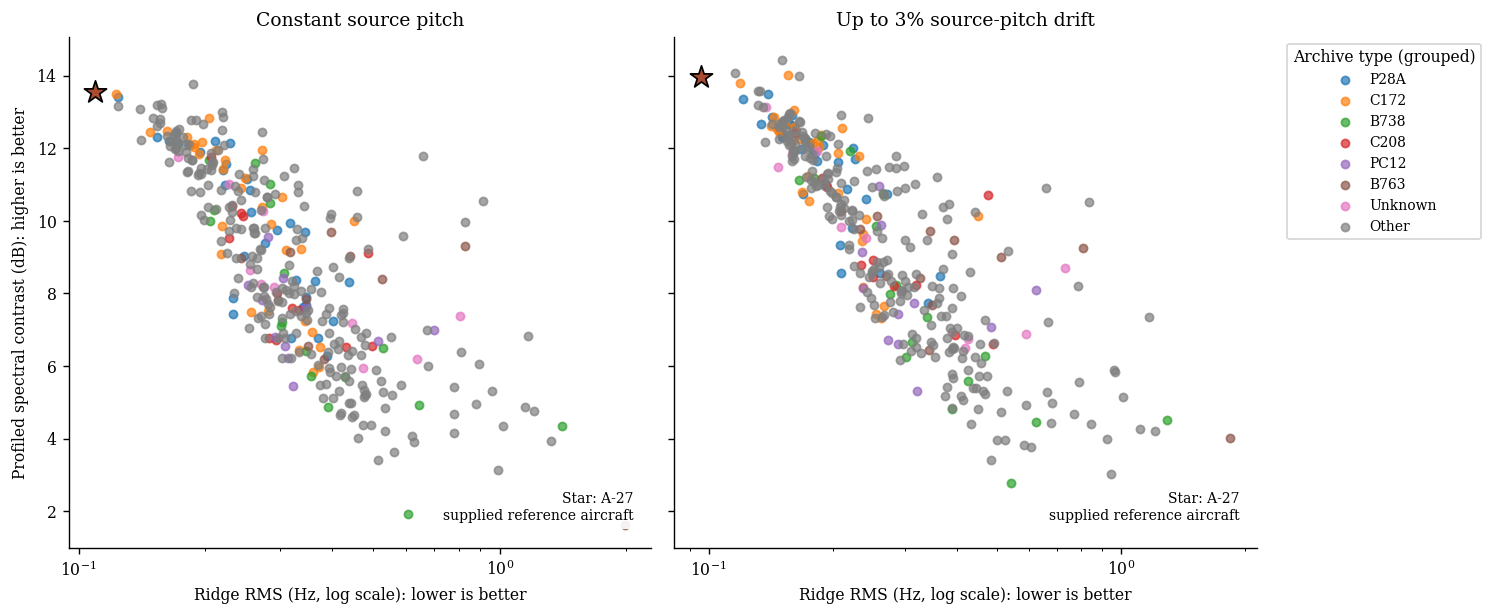

In [6]:
top_types=scores.loc[scores.type.ne('Unknown'),'type'].value_counts().head(6).index.tolist()
group=scores.type.where(scores.type.isin(top_types+['Unknown']),'Other')
groups=top_types+['Unknown','Other']
palette={g:plt.get_cmap('tab10')(i) for i,g in enumerate(groups)}
fig,axes=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,prefix,title in zip(axes,['constant','drift3'],['Constant source pitch','Up to 3% source-pitch drift']):
    for typ in groups:
        q=scores[group.eq(typ)]
        ax.scatter(q[prefix+'_rms_score'],q[prefix+'_brightness_score'],color=palette[typ],label=typ,s=22,alpha=.7)
    target=scores[scores.label.eq('A-27')].iloc[0]
    ax.scatter(target[prefix+'_rms_score'],target[prefix+'_brightness_score'],s=180,marker='*',facecolors='#A84B32',edgecolors='black',linewidths=1,zorder=5)
    ax.text(.97,.05,'Star: A-27\nsupplied reference aircraft',transform=ax.transAxes,ha='right',va='bottom',fontsize=8,bbox=dict(facecolor='white',alpha=.9,edgecolor='none'))
    ax.set_xscale('log')
    ax.set(title=title,xlabel='Ridge RMS (Hz, log scale): lower is better')
axes[0].set_ylabel('Profiled spectral contrast (dB): higher is better')
axes[1].legend(title='Archive type (grouped)',bbox_to_anchor=(1.04,1),fontsize=8)
plt.tight_layout();plt.show()

## 5. Search coverage and ranking

The table includes the union of candidates retained by the documented coarse ranking rule, not every aircraft in the archive. Missing fits are not negative evidence. Spectral ranks are among retained ridge-screened geometry modes, not an independent exhaustive spectral search. Lower ridge RMS and higher spectral contrast are better; neither is a probability.

The 42-candidate upload-time cohort is historical and is **not** the corrected recording-time cohort.

In [7]:
import json
summary=json.loads(INPUTS['corrected_search_summary.json'])
display(pd.Series({k:summary[k] for k in ['archive_files','coarse_aircraft','coarse_covered_aircraft','selected_for_refinement','refined_covered_aircraft']}))
display(pd.DataFrame(summary['target_scores']).T)
assert scores.constant_rms_rank.notna().sum()==358
assert scores.drift3_rms_rank.notna().sum()==358
print(summary['refinement_rule'])
print(summary['pixel_scope'])

archive_files               75222
coarse_aircraft              6743
coarse_covered_aircraft      3880
selected_for_refinement       361
refined_covered_aircraft      359
dtype: int64

,rank,rms_hz,profiled_brightness_db
0|rms_hz,1.0,0.109325,13.413069
0|profiled_brightness_db,2.0,0.111567,13.551919
0.03|rms_hz,1.0,0.095596,13.906659
0.03|profiled_brightness_db,5.0,0.095811,13.966583


Union of top200aircraft for each of two source models and two coarse objectives, not an identity/location filter
Ranking among retained ridge-screened geometry modes, not independent exhaustive pixel optimization


## 6. Post-freeze comparison with the approximate reference

The inferred points were frozen before the comparison calculation. The participant's approximate recording location is withheld from this public package. Only scalar separation errors are shown: no coordinates, bearings, or map. These distances are **not** confidence radii and reference precision is limited.

The search happened after disclosure, although identity/location were excluded from fitting inputs. A strong retrospective agreement is not a blind-identification claim. Alternative spatial solutions remain plausible; there is no calibrated 95% region or unique observer pin.

,source_model,objective,rank,ranked_candidates,distance_to_reference_m,rms_hz
0,constant,curve_rms,1,358,56.5016,0.1093
1,bounded_3pct_drift,curve_rms,1,358,79.0624,0.0956
2,constant,spectral_contrast,2,358,167.5713,0.1116
3,bounded_3pct_drift,spectral_contrast,5,358,158.6436,0.0958


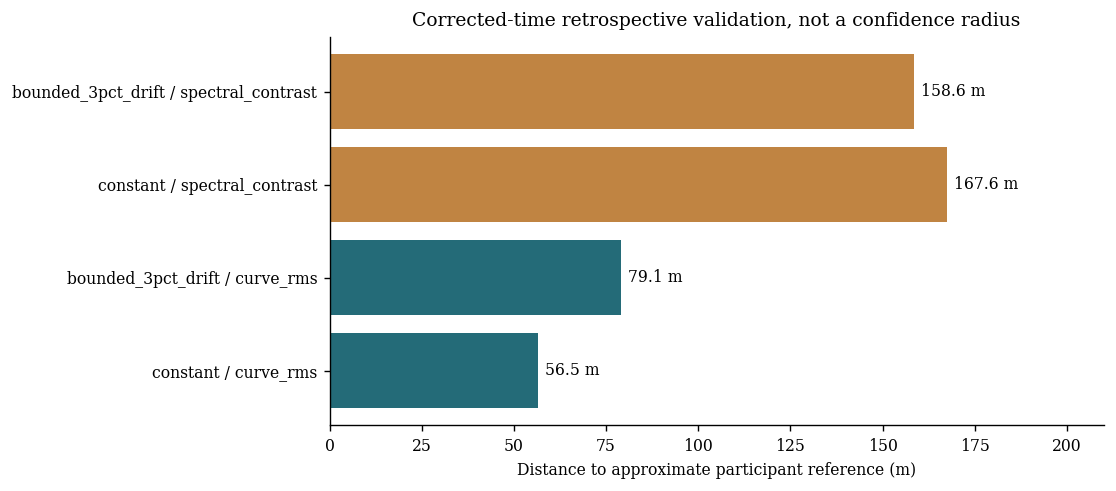

In [8]:
validation=csv_input('corrected_location_validation.csv')
display(validation.round(4))
fig,ax=plt.subplots(figsize=(9,4))
labels=validation.source_model+' / '+validation.objective
bars=ax.barh(labels,validation.distance_to_reference_m,color=['#246b78','#246b78','#c08442','#c08442'])
ax.bar_label(bars,fmt='%.1f m',padding=4)
ax.set(xlabel='Distance to approximate participant reference (m)',title='Corrected-time retrospective validation, not a confidence radius',xlim=(0,210))
plt.tight_layout();plt.show()

### 6.1 What the retained-data comparison does and does not establish

A-27 ranks first of 358 by curve RMS under both source models, but second and fifth by the spectral objectives. Its curve-optimal inferred points are approximately 56.5 m and 79.1 m from the participant reference. This is a promising **post-disclosure, corrected-time** result, not proof of unique identity or a general accuracy guarantee.

The private diagnostics also retain an alternative near-optimal spatial basin roughly 2.5 km away. A preregistered blind test with independent recordings, measured clock accuracy and withheld reference coordinates is needed next. Public tables reproduce these displays; full trajectory/environment fitting requires the private archived inputs.

## 7. Geometry and indoor recording conditions

Aircraft altitude above the adopted datum, terrain elevation and observer/microphone height must be distinguished. Observer altitude is ground elevation plus microphone height; the aircraft-to-observer vertical gap is not the full slant distance. The following diagram is conceptual, not a map or a measured location.

Low-frequency aircraft sound may remain measurable indoors depending on construction, openings, noise and hardware. This possibility does not independently validate an indoor location or this recording. The manuscript supplies the FAA/PARTNER references and limitations.

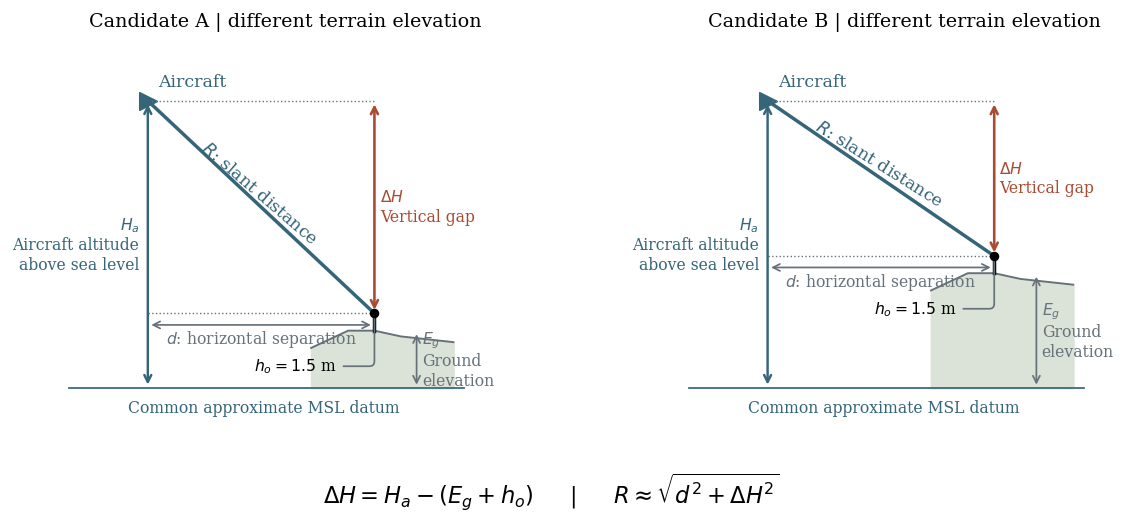

In [9]:
"""Conceptual geometry, not measured candidate locations or a map."""
from pathlib import Path
import numpy as np
import matplotlib

import matplotlib.pyplot as plt

plt.rcParams.update({'font.family':'DejaVu Serif','font.size':10})
fig,axes=plt.subplots(1,2,figsize=(10,4.4))
blue='#356579'; orange='#A84B32'; gray='#67717a'
for ax,g,label in zip(axes,[1.0,2.0],['Candidate A','Candidate B']):
 ax.set_xlim(-1.6,6.8);ax.set_ylim(-.7,6);ax.axis('off')
 ax.plot([-1.5,6],[0,0],color=blue,lw=1);ax.text(2.2,-.42,'Common approximate MSL datum',ha='center',fontsize=9,color=blue)
 x=4.3;Ha=5;h=.3;y=g+h
 ax.fill_between([3.1,3.8,4.3,4.8,5.8],[g-.3,g,g,g-.1,g-.2],0,color='#dbe2d8')
 ax.plot([3.1,3.8,4.3,4.8,5.8],[g-.3,g,g,g-.1,g-.2],color=gray,lw=1.1)
 ax.plot([x,x],[g,y],color='black',lw=2);ax.scatter([x],[y],color='black',s=20,zorder=5)
 ax.scatter([0],[Ha],marker='>',s=100,color=blue);ax.text(.2,Ha+.25,'Aircraft',fontsize=10,color=blue)
 ax.annotate('',(0,0),(0,Ha),arrowprops={'arrowstyle':'<->','color':blue,'lw':1.4});ax.text(-.16,Ha/2,r'$H_a$'+'\nAircraft altitude\nabove sea level',ha='right',va='center',fontsize=9,color=blue)
 ax.plot([0,x],[Ha,Ha],color=gray,ls=':',lw=.8);ax.plot([0,x],[y,y],color=gray,ls=':',lw=.8)
 ax.annotate('',(x+.8,0),(x+.8,g),arrowprops={'arrowstyle':'<->','color':gray});ax.text(x+.9,g/2,r'$E_g$'+'\nGround\nelevation',fontsize=9,va='center',color=gray)
 ax.annotate('',(x,Ha),(x,y),arrowprops={'arrowstyle':'<->','color':orange,'lw':1.5});ax.text(x+.1,(Ha+y)/2,r'$\Delta H$'+'\nVertical gap',fontsize=9,va='center',color=orange)
 ax.plot([0,x],[Ha,y],color=blue,lw=2);angle=np.degrees(np.arctan2(y-Ha,x));ax.text(x*.48,(Ha+y)/2+.18,r'$R$: slant distance',rotation=angle,rotation_mode='anchor',ha='center',fontsize=10,color=blue)
 ax.annotate('',(0,y-.2),(x,y-.2),arrowprops={'arrowstyle':'<->','color':gray});ax.text(x/2,y-.53,r'$d$: horizontal separation',ha='center',fontsize=9,color=gray)
 ax.annotate(r'$h_o=1.5$ m',(x,y),(x-1.5,g-.7),fontsize=9,ha='center',arrowprops={'arrowstyle':'-','color':gray,'connectionstyle':'angle,angleA=0,angleB=-90,rad=5'})
 ax.set_title(label+' | different terrain elevation',fontsize=11,pad=10)
fig.text(.5,.025,r'$\Delta H=H_a-(E_g+h_o)$     |     $R\approx\sqrt{d^2+\Delta H^2}$',ha='center',fontsize=13)
fig.subplots_adjust(bottom=.16,wspace=.4,left=.11,right=.96,top=.86)

plt.show()

## 8. Synthetic propagation: implementation checks, not observed evidence

All coordinates and trajectories below are invented. The included module equations allow independent inspection and execution inside this one file. Synthetic tests verify mathematical consistency, not empirical location accuracy.

In [10]:
"""Uniform-wind acoustic propagation in Cartesian metres; no real locations.

The trajectory callable returns position and ground-relative velocity arrays for
emission times. This readable public module contains the model equations, not
private aircraft trajectories or the full historical search orchestration.
"""
import numpy as np

def propagation(trajectory, emission_time_s, observer_m, sound_speed_m_s=343., wind_m_s=(0.,0.,0.)):
    t=np.atleast_1d(emission_time_s).astype(float)
    p,v=trajectory(t);w=np.asarray(wind_m_s,float);c=float(sound_speed_m_s)
    if c<=0 or w@w>=c*c:raise ValueError('Require positive c and subsonic wind')
    q=np.asarray(observer_m,float)-p;a=c*c-w@w;b=q@w
    lag=(-b+np.sqrt(b*b+a*np.sum(q*q,axis=1)))/a
    ray=q-lag[:,None]*w;norm=np.linalg.norm(ray,axis=1)
    if np.any(norm==0):raise ValueError('Coincident listener and source')
    n=ray/norm[:,None];derivative=1-np.sum(n*v,axis=1)/(c+n@w)
    return lag,derivative,np.sqrt(np.sum(q*q,axis=1))

def received_doppler(trajectory, receive_time_s, observer_m, sound_speed_m_s=343., wind_m_s=(0.,0.,0.)):
    tr=np.atleast_1d(receive_time_s).astype(float);te=tr-10
    for _ in range(20):
        tau,den,_=propagation(trajectory,te,observer_m,sound_speed_m_s,wind_m_s)
        if np.any(den<=0):raise ValueError('Non-monotonic retarded-time branch')
        step=np.clip((te+tau-tr)/den,-100,100);te-=step
        if np.max(np.abs(step))<1e-9:break
    tau,den,distance=propagation(trajectory,te,observer_m,sound_speed_m_s,wind_m_s)
    if np.max(np.abs(te+tau-tr))>1e-6:raise ValueError('Propagation solve did not converge')
    return 1/den,te,distance

def trajectory(t):
    t=np.asarray(t)
    return np.column_stack([65*t,np.full(t.shape,2200.),np.full(t.shape,900.)]),np.column_stack([np.full(t.shape,65.),np.zeros_like(t),np.zeros_like(t)])
observer=np.zeros(3)


### 8.1 Propagation model

Solve reception time as emission time plus acoustic travel time. The frequency factor is the inverse derivative of reception time with respect to emission time. In still air this is \(1/(1+\dot R/c)\); the implemented uniform-wind model adjusts travel time and ray direction. Aircraft altitude alone is not slant range.

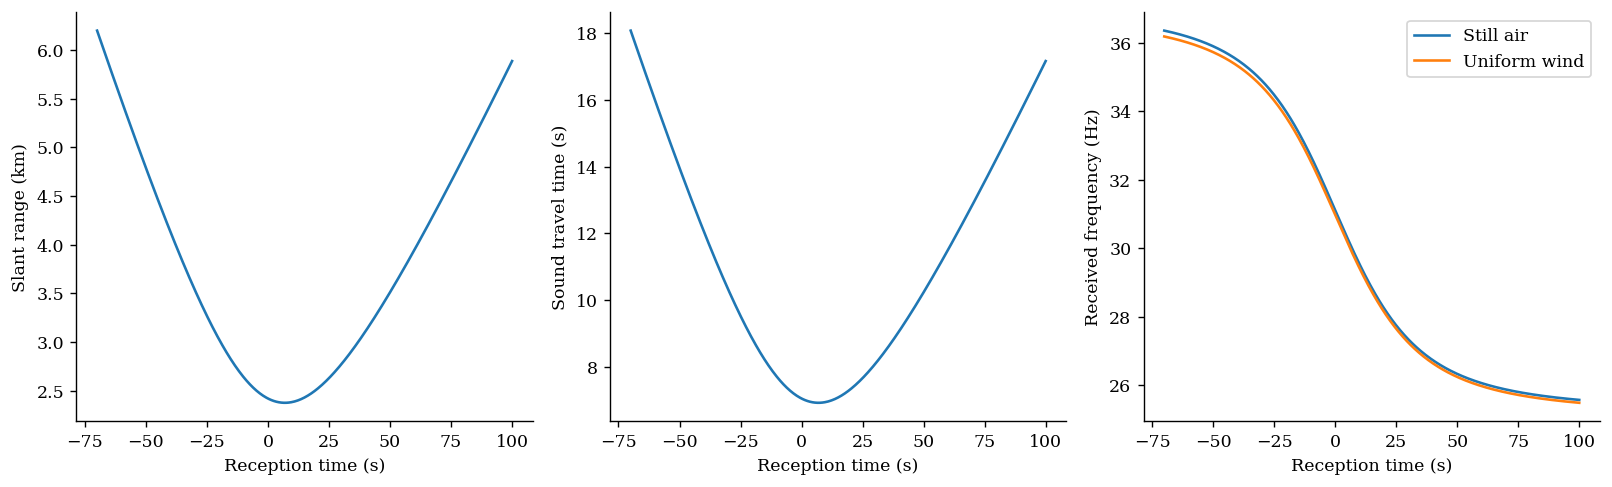

In [11]:
tr=np.linspace(-70,100,501)
factor,te,slant=received_doppler(trajectory,tr,observer)
wind_factor,wind_te,wind_slant=received_doppler(trajectory,tr,observer,wind_m_s=(7.,-4.,1.))
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].plot(tr,slant/1000);axes[0].set(xlabel='Reception time (s)',ylabel='Slant range (km)')
axes[1].plot(tr,tr-te);axes[1].set(xlabel='Reception time (s)',ylabel='Sound travel time (s)')
axes[2].plot(tr,30*factor,label='Still air');axes[2].plot(tr,30*wind_factor,label='Uniform wind')
axes[2].set(xlabel='Reception time (s)',ylabel='Received frequency (Hz)');axes[2].legend()
plt.tight_layout();plt.show()

### 8.2 Numerical checks

Finite-difference agreement, inverse-time recovery and Doppler sign validate implementation consistency only. They do not measure real-world error.

In [12]:
t=np.array([-35.,-10.,20.,50.]);wind=(7.,-4.,1.);eps=1e-3
lag,derivative,_=propagation(trajectory,t,observer,343.,wind)
numeric=1+(propagation(trajectory,t+eps,observer,343.,wind)[0]-propagation(trajectory,t-eps,observer,343.,wind)[0])/(2*eps)
error=np.max(np.abs(derivative-numeric))
_,recovered,_=received_doppler(trajectory,t+lag,observer,343.,wind)
assert error<1e-7
assert np.max(np.abs(recovered-t))<1e-7
print(f'Max derivative error: {error:.3g}; emission-time recovery passed')
p,v=trajectory(t);r=np.linalg.norm(p,axis=1);rdot=np.sum(p*v,axis=1)/r
assert np.allclose(propagation(trajectory,t,observer)[1],1+rdot/343.,atol=1e-12)
print('Still-air Doppler sign check passed')

Max derivative error: 2.02e-11; emission-time recovery passed
Still-air Doppler sign check passed


### 8.3 Mirror ambiguity and pitch drift

For a straight flight path in still air, observers mirrored across its vertical plane can have identical slant-range histories. A near-zero curve mismatch therefore does not guarantee a unique geographic solution. Unknown source pitch introduces another ambiguity.

Mirror observers have indistinguishable Doppler factors in this synthetic geometry.


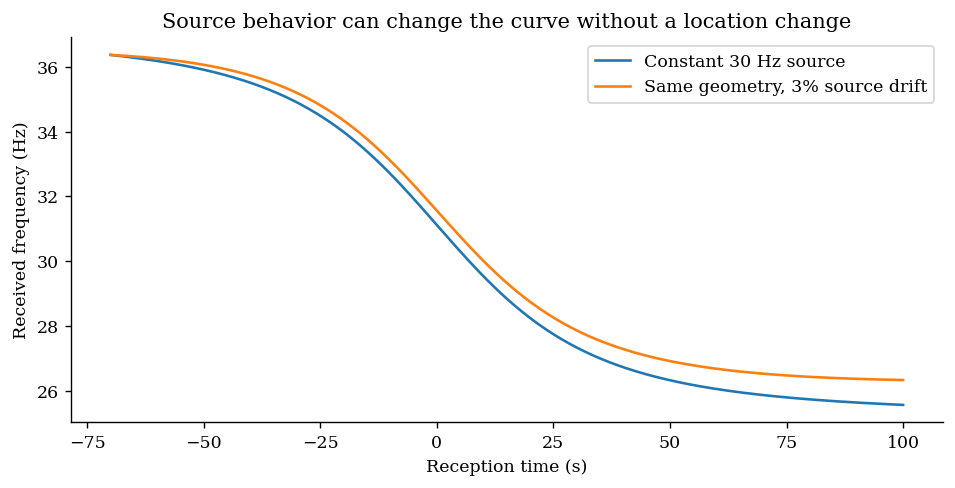

In [13]:
mirror=np.array([0.,4400.,0.])
mirrored,_,_=received_doppler(trajectory,tr,mirror)
assert np.allclose(factor,mirrored,atol=1e-12)
print('Mirror observers have indistinguishable Doppler factors in this synthetic geometry.')
source=30*(1+0.03*(te-te.min())/(te.max()-te.min()))
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(tr,30*factor,label='Constant 30 Hz source')
ax.plot(tr,source*factor,label='Same geometry, 3% source drift')
ax.set(xlabel='Reception time (s)',ylabel='Received frequency (Hz)',title='Source behavior can change the curve without a location change')
ax.legend();plt.show()

## 9. Conclusion and next experiment

Retarded time and three-dimensional geometry are necessary but not sufficient. Independent events, accurately constrained source behavior, propagation conditions and held-out validation are needed before making strong localization claims. This notebook deliberately stops short of a real-data geolocation claim.